## Multiplicação de Matrizes Paralela
### Programação Paralela e Distribuída (2026/2) - UFSCar

**Integrantes**
- Enzo Dezem Alves - 801743
- Gustavo Cesar Bento Laurindo - 821402
- Gustavo de Oliveira Gimenes - 820759
- Tiago de Paula Evangelista - 824369

### Introdução

Este trabalho aplica os conhecimentos teóricos e práticos da disciplina no estudo e no desenvolvimento de uma aplicação paralela relevante. O problema escolhido é a **multiplicação de matrizes**, retirado do conjunto da Maratona de Programação Paralela (SBAC-PAD). É uma operação central em computação científica, aprendizado de máquina e simulações numéricas, e seu alto custo computacional ($O(n^3)$) a torna um bom caso para explorar diferentes modelos de paralelismo.

Partindo de uma versão sequencial de referência, o problema é modelado e decomposto em tarefas independentes, e então implementado em três plataformas:

- **Memória compartilhada**, com threads usando OpenMP;
- **Memória distribuída**, com passagem de mensagens usando MPI;
- **GPU**, explorando o paralelismo massivo de dados com CUDA.

Mais do que apenas paralelizar, o objetivo é justificar as decisões de projeto de cada versão, analisando o impacto da comunicação, da granularidade das tarefas e do balanceamento de carga no desempenho obtido. Ao final, as implementações são comparadas em uma análise de desempenho (tempo de execução, speedup e eficiência).

### Utilitários

Infraestrutura compartilhada por todas as implementações: a medição de tempo padronizada, usada na análise de desempenho, e as funções que geram os diagramas.

#### Execução e medição

No Colab, abra este arquivo e execute as células em ordem. Para executar CUDA, selecione **Ambiente de execução → Alterar tipo de ambiente de execução → GPU**. Em Linux ou WSL, são necessários Jupyter, GCC com OpenMP, Open MPI (`mpicc` e `mpirun`) e, para a GPU, o CUDA Toolkit (`nvcc`). O notebook inclui os códigos e compila cópias em um diretório temporário.

Todos os programas recebem `n m p` para $A_{n\times m} B_{m\times p}$, ou apenas `n` para matrizes quadradas. O código usa `double`, armazenamento contíguo por linhas e entradas determinísticas. Cada execução emite `RESULT,implementação,n,m,p,workers,tempo_s,checksum`. O campo `workers` indica threads no OpenMP, ranks no MPI e blocos lançados em CUDA.

O tempo mede a obtenção de $C$ com $A$ e $B$ já inicializadas na memória do host (ou do rank 0). Inclui a região paralela OpenMP, as três coletivas MPI e as cópias CPU ↔ GPU. A criação de processos MPI, a alocação, a inicialização e a validação são executadas fora da região cronometrada. O tempo total com inicialização do processo é medido separadamente na seção de *hotspot*.

In [1]:
import os
from pathlib import Path
import shlex
import shutil
import statistics
import subprocess
import tempfile
from datetime import datetime, timezone

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

RUN_DIR = Path.cwd()
BUILD = Path(tempfile.mkdtemp(prefix="matmul-"))
SRC, BIN = BUILD / "src", BUILD / "bin"
SRC.mkdir()
BIN.mkdir()

SIZES = [int(n) for n in os.getenv("MATMUL_SIZES", "256 512 1024 2048 4096").split()]
REPS = int(os.getenv("MATMUL_REPS", "5"))
CPUS = min(16, len(os.sched_getaffinity(0)))   # até 16 threads/ranks (todas as threads da máquina de testes)
THREADS = sorted({1, CPUS} | {t for t in (2, 4, 8) if t <= CPUS})
RESULTS = []
LOCAL_RUN = "local"
RUN_DATE = datetime.now(timezone.utc).isoformat(timespec="seconds")
CPU_MODEL = next(
    (line.partition(":")[2].strip() for line in Path("/proc/cpuinfo").read_text().splitlines()
     if line.startswith("model name")), "consulte lscpu"
)
GPU_INFO = ""

if Path("/content").is_dir() and not all(shutil.which(x) for x in ("mpicc", "mpirun")):
    subprocess.run(["apt-get", "update", "-qq"], check=True)
    subprocess.run(["apt-get", "install", "-y", "-qq", "openmpi-bin", "libopenmpi-dev"], check=True)

print(f"{RUN_DATE}\n{CPU_MODEL}\n{os.uname().release}\nThreads testadas: {THREADS}")
print(subprocess.check_output(["gcc", "--version"], text=True).splitlines()[0])


def write_source(name, text):
    (SRC / name).write_text(text, encoding="utf-8")
    print(f"Fonte preparada: {name}")


def compile_c(src, out, compiler="gcc", flags="-O3"):
    cmd = [compiler, *shlex.split(flags), str(SRC / src), "-o", str(BIN / out)]
    subprocess.run(cmd, check=True)
    print(shlex.join(cmd))


def parse_output(stdout):
    record, detail = None, None
    for line in stdout.splitlines():
        if line.startswith("RESULT,"):
            _, impl, n, m, p, workers, elapsed, check = line.split(",")
            if record is not None:
                raise ValueError("A execução emitiu mais de uma linha RESULT")
            record = dict(impl=impl, n=int(n), m=int(m), p=int(p), workers=int(workers),
                          time_s=float(elapsed), checksum=float(check), nodes=1)
        elif line.startswith("DETAIL,"):
            detail = line.split(",")[1:]
    if record is None or record["time_s"] <= 0:
        raise ValueError(f"RESULT ausente ou tempo inválido\n{stdout}")
    if record["impl"] == "mpi":
        _, nodes, scatter, bcast, compute, gather = detail
        record.update(nodes=int(nodes), scatter_s=float(scatter), bcast_s=float(bcast),
                      compute_max_s=float(compute), gather_s=float(gather))
    elif record["impl"] == "cuda":
        _, h2d, kernel, d2h = detail
        record.update(h2d_s=float(h2d), kernel_s=float(kernel), d2h_s=float(d2h))
    return record


def run_once(cmd, env=None):
    result = subprocess.run(shlex.split(cmd), capture_output=True, text=True, timeout=120,
                            env={**os.environ, "MATMUL_VERIFY": "0", **(env or {})})
    if result.returncode:
        raise RuntimeError(f"Falha em {cmd}\n{result.stdout}\n{result.stderr}")
    return parse_output(result.stdout)


def benchmark(cmd, reps=REPS, env=None, phase="principal"):
    runs = [run_once(cmd, env) for _ in range(reps)]
    for rep, record in enumerate(runs, start=1):
        RESULTS.append({**record, "rep": rep, "run": LOCAL_RUN, "phase": phase})
    times = [r["time_s"] for r in runs]
    mean = statistics.mean(times)
    std = statistics.stdev(times) if reps > 1 else 0.0
    r0 = runs[0]
    print(f"{r0['impl']:<19} n={r0['n']:>4} workers={r0['workers']:>4} | {mean:.6f} ± {std:.6f} s")
    return {**r0, "mean_s": mean, "std_s": std}


def results_table():
    df = pd.DataFrame(RESULTS).query("phase == 'principal'")
    return (df.groupby(["impl", "n", "m", "p", "workers"])
              .agg(mean_s=("time_s", "mean"), std_s=("time_s", "std"))
              .reset_index())

2026-11-19T18:46:56+00:00
13th Gen Intel(R) Core(TM) i5-13450HX
7.0.0-43-generic
Threads testadas: [1, 2, 4, 8, 16]
gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0


In [2]:
write_source('common.h', r"""/* Infraestrutura comum a todas as implementações de multiplicação de matrizes.
 * Notação do enunciado: A (n x m) * B (m x p) = C (n x p), com c_ik = sum_j a_ij * b_jk. */
#ifndef COMMON_H
#define COMMON_H

#ifndef _POSIX_C_SOURCE
#define _POSIX_C_SOURCE 199309L
#endif
#include <errno.h>
#include <limits.h>
#include <math.h>
#include <stdint.h>
#include <stdio.h>
#include <stdlib.h>
#include <string.h>
#include <time.h>

typedef struct { int n, m, p; } dims_t;

/* restrict é palavra-chave de C; em C++ (CUDA) o equivalente é __restrict__. */
#ifdef __cplusplus
#define MATMUL_RESTRICT __restrict__
#else
#define MATMUL_RESTRICT restrict
#endif

/* Tempo de parede em segundos (relógio monotônico, imune a ajustes do relógio do sistema). */
static inline double wall_time(void) {
    struct timespec ts;
    clock_gettime(CLOCK_MONOTONIC, &ts);
    return ts.tv_sec + ts.tv_nsec * 1e-9;
}

static inline int positive_int(const char *text) {
    char *end;
    errno = 0;
    long value = strtol(text, &end, 10);
    return (errno || end == text || *end || value <= 0 || value > INT_MAX)
        ? 0 : (int)value;
}

/* Lê as dimensões sem encerrar o programa: devolve 1 se forem válidas.
 * "prog n m p", ou "prog n" para matrizes quadradas (padrão: 1024). */
static inline int try_parse_dims(int argc, char **argv, dims_t *d) {
    *d = (dims_t){1024, 1024, 1024};
    if (argc == 4) {
        d->n = positive_int(argv[1]);
        d->m = positive_int(argv[2]);
        d->p = positive_int(argv[3]);
    } else if (argc != 1)
        d->n = d->m = d->p = (argc == 2) ? positive_int(argv[1]) : 0;
    return d->n > 0 && d->m > 0 && d->p > 0;
}

static inline void print_usage(const char *prog) {
    fprintf(stderr, "Uso: %s n [m p]  (dimensões positivas)\n", prog);
}

/* Versão usada pelos programas sem MPI: encerra com a mensagem de uso se as dimensões forem inválidas. */
static inline dims_t parse_dims(int argc, char **argv) {
    dims_t d;
    if (!try_parse_dims(argc, argv, &d)) {
        print_usage(argv[0]);
        exit(EXIT_FAILURE);
    }
    return d;
}

/* Aloca uma matriz rows x cols contígua (row-major), opcionalmente zerada. */
static inline double *alloc_matrix(int rows, int cols, int zero) {
    if ((size_t)rows > SIZE_MAX / sizeof(double) / (size_t)cols) {
        fprintf(stderr, "Dimensões excedem o tamanho máximo de alocação\n");
        exit(EXIT_FAILURE);
    }
    size_t count = (size_t)rows * cols;
    if (count == 0) count = 1; /* Um buffer válido para ranks sem linhas. */
    double *M = (double *)(zero ? calloc(count, sizeof(double)) : malloc(count * sizeof(double)));
    if (!M) { fprintf(stderr, "Falha ao alocar %zu bytes\n", count * sizeof(double)); exit(EXIT_FAILURE); }
    return M;
}

/* Preenchimento determinístico: todas as versões multiplicam as mesmas matrizes.
 * a_ij para 0 <= i < n, 0 <= j < m;  b_jk para 0 <= j < m, 0 <= k < p. */
static inline void init_matrices(dims_t d, double *A, double *B) {
    for (int i = 0; i < d.n; i++)
        for (int j = 0; j < d.m; j++)
            A[(size_t)i * d.m + j] = (((size_t)i * 7 + (size_t)j * 3) % 11) / 10.0;
    for (int j = 0; j < d.m; j++)
        for (int k = 0; k < d.p; k++)
            B[(size_t)j * d.p + k] = (((size_t)j * 5 + (size_t)k * 2) % 13) / 10.0;
}

/* Núcleo de cálculo comum às versões de CPU: acumula em C as linhas [row_begin, row_end).
 * Ordem i-j-k: o laço interno (k) percorre B[j][.] e C[i][.] com stride 1.
 * Usar a mesma função na versão sequencial, no OpenMP e no MPI garante que o compilador
 * gere o mesmo código para o laço, e o speedup mede só o efeito da paralelização. */
static inline void matmul_rows(dims_t d, int row_begin, int row_end,
                               const double *MATMUL_RESTRICT A, const double *MATMUL_RESTRICT B,
                               double *MATMUL_RESTRICT C) {
    const int m = d.m, p = d.p;
    for (int i = row_begin; i < row_end; i++)
        for (int j = 0; j < m; j++) {
            const double a_ij = A[(size_t)i * m + j];
            for (int k = 0; k < p; k++)
                C[(size_t)i * p + k] += a_ij * B[(size_t)j * p + k];
        }
}

/* Ative em casos pequenos para conferir cada elemento por produto escalar. */
static inline int verify_matrix(dims_t d, const double *A, const double *B, const double *C) {
    const char *enabled = getenv("MATMUL_VERIFY");
    if (!enabled || strcmp(enabled, "1") != 0) return 1;

    for (int i = 0; i < d.n; i++)
        for (int k = 0; k < d.p; k++) {
            double expected = 0.0;
            for (int j = 0; j < d.m; j++)
                expected += A[(size_t)i * d.m + j] * B[(size_t)j * d.p + k];
            double actual = C[(size_t)i * d.p + k];
            if (!(fabs(actual - expected) <= 1e-12 + 1e-10 * fabs(expected))) {
                fprintf(stderr, "C[%d,%d] = %.17g, esperado %.17g\n", i, k, actual, expected);
                return 0;
            }
        }
    return 1;
}

/* Soma de todos os elementos de C (n x p), usada para validar as versões paralelas. */
static inline double checksum(dims_t d, const double *C) {
    double s = 0.0;
    for (size_t idx = 0; idx < (size_t)d.n * d.p; idx++) s += C[idx];
    return s;
}

/* Linha padronizada lida pela função benchmark() do notebook. */
static inline void report(const char *impl, dims_t d, int workers, double seconds, double chk) {
    printf("RESULT,%s,%d,%d,%d,%d,%.9f,%.17g\n", impl, d.n, d.m, d.p, workers, seconds, chk);
}

#endif
""")

Fonte preparada: common.h


#### Funções de desenho

Os diagramas são recriados a cada execução. Azul representa $A$, laranja representa $B$ e violeta representa $C$.

In [3]:
# Funções de desenho compartilhadas por todos os diagramas do notebook.
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch

(BUILD / "figuras").mkdir(exist_ok=True)

# Cores fixas por papel: A = azul, B = laranja, C = violeta (paleta segura para daltonismo).
BLUE, ORANGE, VIOLET = "#2a78d6", "#eb6834", "#6250d6"
INK, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#c9c8c2", "#fcfcfb"
# Cores para identificar workers (threads, processos ou blocos), distintas das cores de A, B e C.
WORKER_COLORS = ["#1baf7a", "#eda100", "#e87ba4", "#008300"]

def draw_matrix(ax, x0, y0, rows, cols, title="", fills=None, cell=1.0):
    """Desenha uma grade rows x cols com canto superior esquerdo em (x0, y0).
    fills: {(linha, coluna): cor}. Retorna uma função que dá o centro da célula (r, c)."""
    fills = fills or {}
    for r in range(rows):
        for c in range(cols):
            ax.add_patch(Rectangle((x0 + c * cell, y0 - (r + 1) * cell), cell, cell,
                                   facecolor=fills.get((r, c), SURF), edgecolor=GRID, lw=1.2))
    ax.add_patch(Rectangle((x0, y0 - rows * cell), cols * cell, rows * cell,
                           fill=False, edgecolor=INK, lw=1.6))
    if title:
        ax.text(x0 + cols * cell / 2, y0 + 0.45, title, ha="center", va="bottom", fontsize=12, color=INK)
    return lambda r, c: (x0 + (c + .5) * cell, y0 - (r + .5) * cell)

def product_layout(ax, n, m, p, gap=1.6):
    """Posiciona A (n x m) × B (m x p) = C (n x p) lado a lado; retorna (xa, xb, xc, topo)."""
    xa, xb = 0, m + gap
    xc, top = xb + p + gap, max(n, m)
    ax.text(xa + m + gap / 2, top - n / 2, "×", ha="center", va="center", fontsize=22, color=INK)
    ax.text(xb + p + gap / 2, top - n / 2, "=", ha="center", va="center", fontsize=22, color=INK)
    return xa, xb, xc, top

def arrow(ax, start, end, color=INK):
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=14, color=color, lw=2))

def h_arrow(ax, center_of, row, c0, c1):
    """Seta horizontal atravessando as células (row, c0)..(row, c1)."""
    (x0, y), (x1, _) = center_of(row, c0), center_of(row, c1)
    arrow(ax, (x0 - .3, y), (x1 + .3, y))

def label(ax, xy, text, fontsize=10):
    """Rótulo com fundo claro, legível sobre qualquer preenchimento."""
    ax.text(*xy, text, ha="center", va="center", fontsize=fontsize, color=INK,
            bbox=dict(boxstyle="round,pad=0.2", facecolor=SURF, edgecolor="none", alpha=0.9))

def finish(ax, width, top, bottom=-1.6):
    ax.set_xlim(-0.5, width + 0.5); ax.set_ylim(bottom, top + 1.2)
    ax.set_aspect("equal"); ax.axis("off")

def save_figure(fig, name):
    fig.savefig(BUILD / "figuras" / f"{name}.png", dpi=150, bbox_inches="tight", facecolor=SURF)
    plt.show()

### Implementação sequencial

#### O problema

O produto $C$ de duas matrizes $A$ e $B$ é definido como

$$c_{ik} = \sum_{j} a_{ij} \, b_{jk},$$

em que o índice $j$ é somado para cada par $(i, k)$. No enunciado isso aparece em notação de Einstein, com a soma implícita no índice repetido. Para o produto estar definido, o número de colunas de $A$ deve ser igual ao número de linhas de $B$:

$$(n \times m)\,(m \times p) = (n \times p),$$

ou seja, $A$ tem dimensão $n \times m$, $B$ tem $m \times p$ e $C$ tem $n \times p$, com $0 \le i < n$, $0 \le j < m$ e $0 \le k < p$.

Cada um dos $n \cdot p$ elementos de $C$ exige $m$ multiplicações e $m$ somas, ou seja, $2nmp$ operações de ponto flutuante no total, sobre $nm + mp + np$ valores de dados. Para matrizes quadradas ($n = m = p$) são $2n^3$ operações sobre $3n^2$ dados. Essa razão de $O(n)$ operações por dado faz do problema um caso **limitado por computação**, e não por memória, o que é favorável à paralelização. Além disso, os elementos de $C$ são **independentes entre si**: nenhum $c_{ik}$ depende de outro, o que será a base da decomposição nas próximas seções.

Convenções adotadas em todas as implementações:
- as implementações aceitam quaisquer dimensões $n$, $m$ e $p$. Na análise de desempenho usamos matrizes quadradas ($n = m = p$), que é o padrão para comparar escalabilidade, e os casos retangulares entram na validação;
- matrizes de `double` armazenadas em um **vetor contíguo em ordem por linhas** (*row-major*): o elemento $a_{ij}$ está em `A[i*m + j]`, $b_{jk}$ em `B[j*p + k]` e $c_{ik}$ em `C[i*p + k]`. Esse formato é necessário para enviar blocos com MPI e copiar dados para a GPU sem conversões;
- $A$ e $B$ são preenchidas por uma fórmula determinística, para que todas as versões multipliquem exatamente as mesmas matrizes;
- a correção é verificada por um *checksum* (soma de todos os elementos de $C$), comparado com o resultado da versão sequencial.

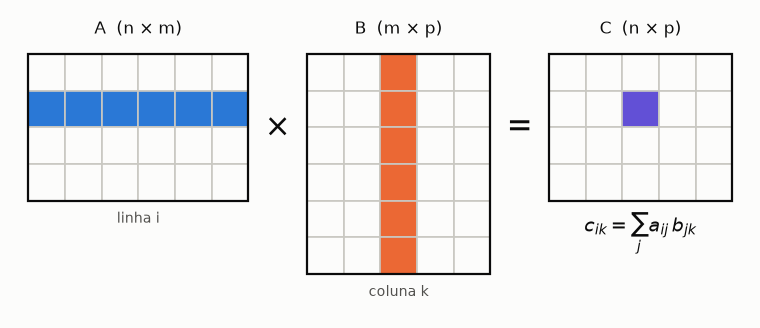

In [4]:
# Figura: definição do problema (linha i de A combinada com a coluna k de B gera c_ik)
n, m, p = 4, 6, 5
i, k = 1, 2

fig, ax = plt.subplots(figsize=(11, 4), facecolor=SURF)
xa, xb, xc, top = product_layout(ax, n, m, p)
draw_matrix(ax, xa, top, n, m, "A  (n × m)", {(i, c): BLUE for c in range(m)})
draw_matrix(ax, xb, top, m, p, "B  (m × p)", {(r, k): ORANGE for r in range(m)})
draw_matrix(ax, xc, top, n, p, "C  (n × p)", {(i, k): VIOLET})
ax.text(xa + m / 2, top - n - 0.3, "linha i", ha="center", va="top", color=MUTED, fontsize=10)
ax.text(xb + p / 2, top - m - 0.3, "coluna k", ha="center", va="top", color=MUTED, fontsize=10)
ax.text(xc + p / 2, top - n - 0.3, r"$c_{ik} = \sum_j a_{ij}\,b_{jk}$", ha="center", va="top",
        fontsize=14, color=INK)
finish(ax, xc + p, top, bottom=top - m - 1.2)
save_figure(fig, "problem")

#### Versão sequencial

A versão sequencial é a **referência** para o cálculo de *speedup* e a validação de todas as outras. Os índices dos laços seguem o enunciado: $i$ percorre as linhas de $C$, $k$ percorre as colunas de $C$ e $j$ é o índice somado.

A tradução direta da fórmula é a ordem **`i-k-j`**, que calcula cada $c_{ik}$ como um produto escalar completo:

```c
for i: for k: for j: C[i][k] += A[i][j] * B[j][k];
```

Nessa ordem, o laço interno percorre `B[j][k]` **por coluna**, com saltos de $p$ elementos na memória, o que gera uma falta de cache a cada acesso. Por isso usamos a ordem **`i-j-k`**:

```c
for i: for j: { a = A[i][j]; for k: C[i][k] += a * B[j][k]; }
```

O resultado é o mesmo, porque a soma em $j$ só muda de posição no aninhamento. Agora o laço interno percorre a linha `B[j][·]` e a linha `C[i][·]` **sequencialmente** (*stride* 1). Isso aproveita as linhas de cache inteiras e permite que o compilador vetorize o laço com instruções SIMD. O número de operações é o mesmo, mas o tempo é muito menor. Usar como referência uma versão sequencial já otimizada evita *speedups* inflados nas versões paralelas.

O laço fica na função `matmul_rows`, em `common.h`, que calcula um intervalo de linhas de $C$. A versão sequencial a chama para todas as linhas, o OpenMP para uma linha por iteração e o MPI para as linhas de cada rank. Com isso, o compilador gera o mesmo código para o laço nas três versões. Isso fez diferença: quando o laço estava escrito diretamente dentro da região OpenMP, o GCC deixava de aplicar uma otimização que aplicava na versão sequencial (calcular duas iterações de $j$ por passagem pela linha de $C$), e o OpenMP com uma thread ficava cerca de 25% mais lento que a versão sequencial, sem relação com o paralelismo.

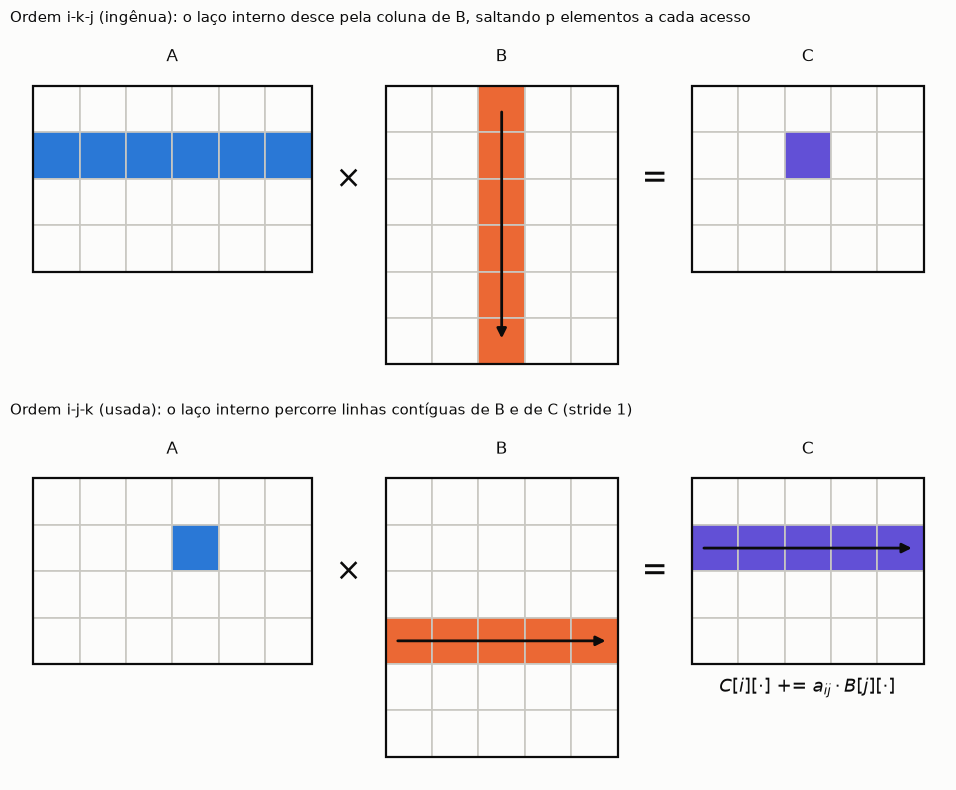

In [5]:
# Figura: padrão de acesso à memória das duas ordens de laço
n, m, p = 4, 6, 5
i, j, k = 1, 3, 2

fig, axes = plt.subplots(2, 1, figsize=(11, 8), facecolor=SURF)

ax = axes[0]  # i-k-j: produto escalar, desce pela coluna de B
xa, xb, xc, top = product_layout(ax, n, m, p)
draw_matrix(ax, xa, top, n, m, "A", {(i, c): BLUE for c in range(m)})
cb = draw_matrix(ax, xb, top, m, p, "B", {(r, k): ORANGE for r in range(m)})
draw_matrix(ax, xc, top, n, p, "C", {(i, k): VIOLET})
arrow(ax, cb(0, k), cb(m - 1, k))
ax.set_title("Ordem i-k-j (ingênua): o laço interno desce pela coluna de B, saltando p elementos a cada acesso",
             fontsize=11, color=INK, loc="left")
finish(ax, xc + p, top, bottom=top - m - 0.5)

ax = axes[1]  # i-j-k: a_ij fixo, percorre linhas de B e C
xa, xb, xc, top = product_layout(ax, n, m, p)
draw_matrix(ax, xa, top, n, m, "A", {(i, j): BLUE})
cb = draw_matrix(ax, xb, top, m, p, "B", {(j, c): ORANGE for c in range(p)})
cc = draw_matrix(ax, xc, top, n, p, "C", {(i, c): VIOLET for c in range(p)})
h_arrow(ax, cb, j, 0, p - 1)
h_arrow(ax, cc, i, 0, p - 1)
ax.text(xc + p / 2, top - n - 0.3, r"$C[i][\cdot]$ += $a_{ij} \cdot B[j][\cdot]$", ha="center", va="top",
        fontsize=13, color=INK)
ax.set_title("Ordem i-j-k (usada): o laço interno percorre linhas contíguas de B e de C (stride 1)",
             fontsize=11, color=INK, loc="left")
finish(ax, xc + p, top, bottom=top - m - 0.5)

fig.tight_layout()
save_figure(fig, "sequential_loop_order")

In [6]:
write_source('sequential.c', r"""#include "common.h"

/* C (n x p) = A (n x m) * B (m x p), c_ik = sum_j a_ij * b_jk.
 * Todas as linhas de C são calculadas pelo núcleo i-j-k de common.h. */
static void matmul_seq(dims_t d, const double *A, const double *B, double *C) {
    matmul_rows(d, 0, d.n, A, B, C);
}

int main(int argc, char **argv) {
    dims_t d = parse_dims(argc, argv);
    double *A = alloc_matrix(d.n, d.m, 0);
    double *B = alloc_matrix(d.m, d.p, 0);
    double *C = alloc_matrix(d.n, d.p, 1);
    init_matrices(d, A, B);

    double t0 = wall_time();
    matmul_seq(d, A, B, C);
    double t1 = wall_time();

    int valid = verify_matrix(d, A, B, C);
    if (valid) report("sequential", d, 1, t1 - t0, checksum(d, C));
    free(A); free(B); free(C);
    return valid ? EXIT_SUCCESS : EXIT_FAILURE;
}
""")

Fonte preparada: sequential.c


Verificamos cada elemento de $C$ com um produto escalar de referência (`MATMUL_VERIFY=1`) e comparamos a soma dos elementos com o NumPy. Os casos incluem matrizes quadradas, retangulares, produtos de vetores e bordas que cruzam blocos CUDA de $16 \times 16$. A verificação roda fora da medição.

In [7]:
compile_c("sequential.c", "sequential")

def reference_checksum(n, m, p):
    """Mesmas matrizes de common.h, multiplicadas pelo NumPy."""
    i, j = np.indices((n, m))
    A = ((i * 7 + j * 3) % 11) / 10.0
    j, k = np.indices((m, p))
    B = ((j * 5 + k * 2) % 13) / 10.0
    return (A @ B).sum()

VALIDATION_CASES = [(256, 256, 256), (300, 200, 400), (513, 127, 64), (1, 1000, 1), (500, 1, 300), (17, 23, 31), (33, 31, 18)]

rows = []
for n, m, p in VALIDATION_CASES:
    res = run_once(f"{BIN}/sequential {n} {m} {p}", env={"MATMUL_VERIFY": "1"})
    ref = reference_checksum(n, m, p)
    rows.append(dict(A=f"{n}×{m}", B=f"{m}×{p}", C=f"{n}×{p}", checksum_C=res["checksum"],
                     checksum_numpy=ref, correto=bool(np.isclose(res["checksum"], ref, rtol=1e-9))))
validation = pd.DataFrame(rows)
assert validation["correto"].all(), "A versão sequencial divergiu do NumPy!"
validation

gcc -O3 /tmp/matmul-dfu8n4bv/src/sequential.c -o /tmp/matmul-dfu8n4bv/bin/sequential


,A,B,C,checksum_C,checksum_numpy,correto
0,256×256,256×256,256×256,5033027.45,5033027.45,True
1,300×200,200×400,300×400,7199976.59,7199976.59,True
2,513×127,127×64,513×64,1250836.31,1250836.31,True
3,1×1000,1000×1,1×1,299.66,299.66,True
4,500×1,1×300,500×300,44867.94,44867.94,True
5,17×23,23×31,17×31,3631.00,3631.00,True
6,33×31,31×18,33×18,5511.00,5511.00,True


A célula abaixo mede o tempo sequencial para matrizes quadradas. Cada tamanho é repetido cinco vezes por padrão e fornece a referência das comparações locais.

In [8]:
for n in SIZES:
    benchmark(f"{BIN}/sequential {n}")

results_table()

sequential          n= 256 workers=   1 | 0.004241 ± 0.000359 s


sequential          n= 512 workers=   1 | 0.027633 ± 0.002395 s


sequential          n=1024 workers=   1 | 0.202139 ± 0.013359 s


sequential          n=2048 workers=   1 | 2.802302 ± 0.059141 s


sequential          n=4096 workers=   1 | 24.144667 ± 0.434542 s


,impl,n,m,p,workers,mean_s,std_s
0,sequential,256,256,256,1,0.004241,0.000359
1,sequential,512,512,512,1,0.027633,0.002395
2,sequential,1024,1024,1024,1,0.202139,0.013359
3,sequential,2048,2048,2048,1,2.802302,0.059141
4,sequential,4096,4096,4096,1,24.144667,0.434542


### Modelagem e estratégia de decomposição

A multiplicação de matrizes é um problema de **paralelismo de dados**: a mesma operação é aplicada a um grande volume de dados, sem dependências entre os resultados. Nesta seção, analisamos onde está o custo do programa, como dividir o trabalho entre os *workers* (threads, processos ou threads da GPU) e quais são os impactos dessa divisão no balanceamento de carga, no uso do cache, na comunicação e na granularidade. As decisões tomadas aqui orientam as três implementações paralelas.

#### Hotspot

O programa tem três etapas: inicializar $A$ e $B$, multiplicar e calcular o *checksum*. A inicialização toca $nm + mp$ elementos e o *checksum* toca $np$, ou seja, as duas são $O(n^2)$ para matrizes quadradas. A multiplicação executa $2nmp$ operações, que é $O(n^3)$. Com $n = 4096$, isso significa cerca de 50 milhões de acessos na inicialização e no *checksum* contra 137 bilhões de operações de ponto flutuante na multiplicação.

O *hotspot* é, portanto, o laço triplo da multiplicação, e é só ele que vale a pena paralelizar. A célula abaixo confirma isso medindo o tempo total do processo e comparando com o tempo da multiplicação reportado pelo próprio programa.

In [9]:
import time

rows = []
for n in [1024, 2048]:
    t0 = time.perf_counter()
    res = run_once(f"{BIN}/sequential {n}")
    total = time.perf_counter() - t0
    rows.append(dict(n=n, tempo_total_s=total, tempo_multiplicacao_s=res["time_s"],
                     fracao_multiplicacao=f"{100 * res['time_s'] / total:.1f}%"))
pd.DataFrame(rows)

,n,tempo_total_s,tempo_multiplicacao_s,fracao_multiplicacao
0,1024,0.196843,0.183421,93.2%
1,2048,2.735720,2.694824,98.5%


O restante inclui a criação do processo, a alocação, a inicialização e o *checksum*. O custo do laço triplo cresce mais rapidamente com o tamanho da matriz. Para a comparação de *speedup*, medimos a obtenção de C e incluímos a comunicação exigida em cada implementação.

#### Decomposição de dados

A fórmula $c_{ik} = \sum_j a_{ij}\,b_{jk}$ tem três índices, e cada um poderia ser dividido entre os *workers*. Os índices $i$ e $k$ identificam elementos diferentes de $C$, que são independentes entre si. Já o índice $j$ é o da soma: dividir $j$ faria vários *workers* acumularem no mesmo $c_{ik}$, o que exige operações atômicas ou uma etapa extra de redução, além de mais comunicação. Por isso adotamos uma **decomposição do resultado** (*output decomposition*): cada *worker* fica responsável por um conjunto de elementos de $C$ e calcula a soma em $j$ inteira, sem precisar se coordenar com os demais.

A figura abaixo mostra três formas de dividir $C$, da mais fina para a mais grossa:

- **por elemento**: cada tarefa calcula um único $c_{ik}$, gerando $n \cdot p$ tarefas de $2m$ operações cada. É granularidade fina demais para threads de CPU, mas é o modelo natural da GPU, que executa milhares de threads leves agrupadas em blocos;
- **por faixas de linhas (1D)**: cada *worker* recebe um bloco de linhas consecutivas de $C$. Para isso, ele precisa da faixa correspondente de $A$ e da matriz $B$ inteira;
- **por blocos 2D**: os *workers* formam uma grade e cada um calcula um bloco de $C$. Cada *worker* precisa de uma faixa de linhas de $A$ e de uma faixa de colunas de $B$, e não mais de $B$ inteira.

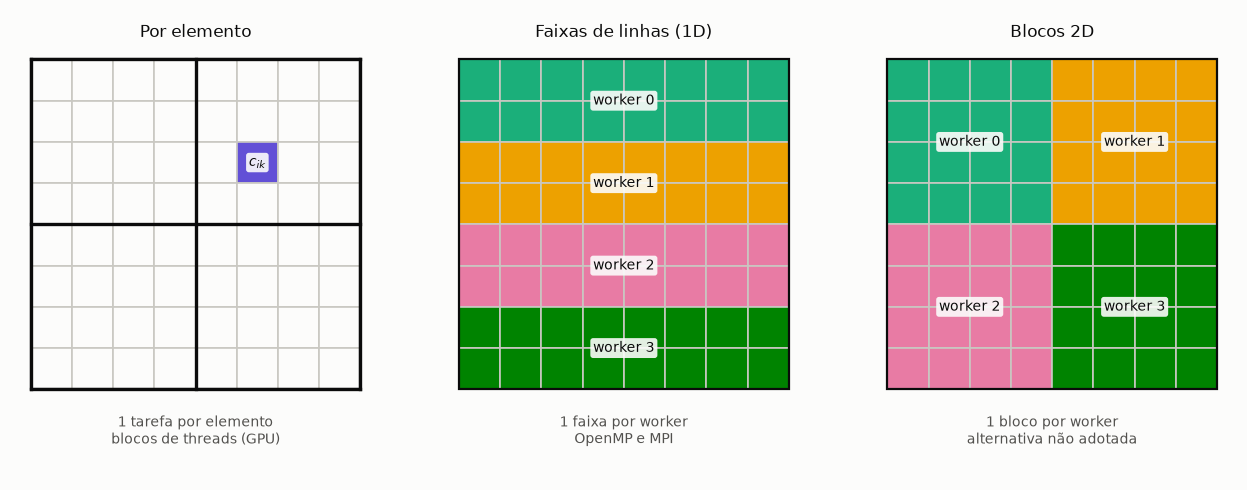

In [10]:
# Figura: três formas de decompor C entre os workers
N = 8
fig, axes = plt.subplots(1, 3, figsize=(13, 5), facecolor=SURF)

ax = axes[0]  # por elemento, agrupados em blocos de threads (GPU)
cc = draw_matrix(ax, 0, N, N, N, "Por elemento", {(2, 5): VIOLET})
for t in range(0, N + 1, 4):  # fronteiras dos blocos de threads
    ax.plot([t, t], [0, N], color=INK, lw=2.4); ax.plot([0, N], [t, t], color=INK, lw=2.4)
label(ax, cc(2, 5), r"$c_{ik}$", 10)
ax.text(N / 2, -0.6, "1 tarefa por elemento\nblocos de threads (GPU)", ha="center", va="top", fontsize=10, color=MUTED)
finish(ax, N, N, bottom=-2.2)

ax = axes[1]  # faixas de linhas 1D
fills = {(r, c): WORKER_COLORS[r // 2] for r in range(N) for c in range(N)}
cc = draw_matrix(ax, 0, N, N, N, "Faixas de linhas (1D)", fills)
for w in range(4):
    label(ax, (N / 2, N - 2 * w - 1), f"worker {w}")
ax.text(N / 2, -0.6, "1 faixa por worker\nOpenMP e MPI", ha="center", va="top", fontsize=10, color=MUTED)
finish(ax, N, N, bottom=-2.2)

ax = axes[2]  # blocos 2D
fills = {(r, c): WORKER_COLORS[2 * (r // 4) + c // 4] for r in range(N) for c in range(N)}
draw_matrix(ax, 0, N, N, N, "Blocos 2D", fills)
for w in range(4):
    label(ax, (2 + 4 * (w % 2), N - 2 - 4 * (w // 2)), f"worker {w}")
ax.text(N / 2, -0.6, "1 bloco por worker\nalternativa não adotada", ha="center", va="top", fontsize=10, color=MUTED)
finish(ax, N, N, bottom=-2.2)

fig.tight_layout()
save_figure(fig, "decomposition_options")

Nas versões OpenMP e MPI, dividimos $C$ em faixas de linhas. Cada faixa de $A$ e $C$ é contígua em memória. As faixas dão a cada *worker* uma região própria de escrita e preservam o laço interno da referência sequencial. Com `static`, uma faixa por thread já equilibra o número de linhas. Com `dynamic` e `guided`, o runtime pode entregar vários *chunks* à mesma thread.

A grade 2D de processos pode reduzir a replicação de dados em grande escala, mas exige trocar painéis entre grupos de processos. Escolhemos faixas 1D para trabalhar com poucos ranks e medir diretamente a comunicação de cada coletiva. Em CUDA, cada thread calcula um elemento de $C$ e cada bloco cobre um *tile*.

#### Balanceamento de carga

Cada elemento de $C$ acumula $m$ produtos. Se $n$ não é divisível por $P$, os primeiros $n \bmod P$ ranks recebem $\lfloor n/P\rfloor + 1$ linhas. Os demais recebem $\lfloor n/P\rfloor$. A diferença máxima é uma linha. Com $n = 4096$ e $P = 12$, são 342 ou 341 linhas, cerca de 0,3% de diferença. A figura ilustra a divisão de 10 linhas entre 4 *workers*.

Em um processador com núcleos de capacidades diferentes, a mesma quantidade de linhas pode levar tempos diferentes. Testamos `static`, `dynamic` e `guided` em OpenMP para medir se redistribuir *chunks* reduz a espera. Em MPI, a distribuição é fixa e a reunião de $C$ depende de todos os ranks.

Se $n < P$, alguns *workers* ficam sem trabalho. O programa MPI usa contagens zero para esses ranks e todos participam das coletivas. Na GPU, blocos que cruzam a borda carregam zeros nas posições fora das matrizes, e apenas threads com coordenadas válidas gravam em $C$.

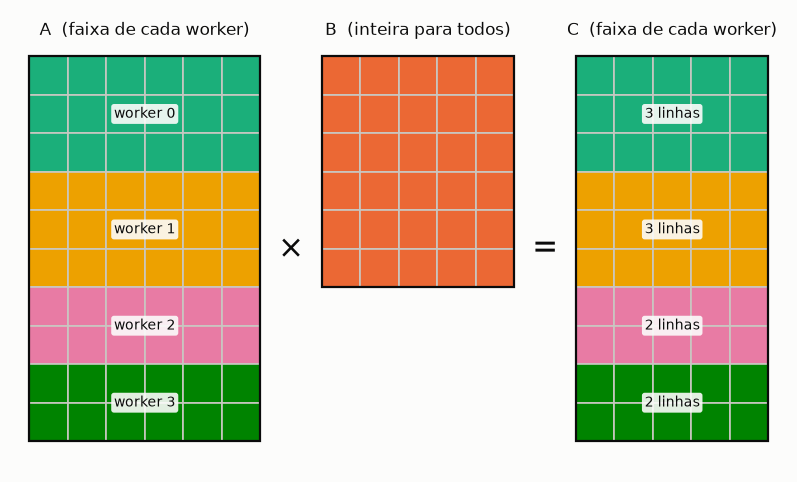

Divisão para n = 4096:
  P =  4: 1024 a 1024 linhas por worker (desbalanceamento de 0.00%)
  P = 12: 342 a 341 linhas por worker (desbalanceamento de 0.29%)
  P = 16: 256 a 256 linhas por worker (desbalanceamento de 0.00%)


In [11]:
def row_ranges(n, workers):
    """Divide n linhas entre workers: os primeiros n % workers recebem uma linha a mais."""
    base, extra = divmod(n, workers)
    ranges, start = [], 0
    for w in range(workers):
        size = base + (1 if w < extra else 0)
        ranges.append((start, start + size))
        start += size
    return ranges

# Figura: decomposição 1D por linhas com divisão não exata (n = 10, P = 4)
n, m, p, workers = 10, 6, 5, 4
ranges = row_ranges(n, workers)
owner = {r: w for w, (a, b) in enumerate(ranges) for r in range(a, b)}

fig, ax = plt.subplots(figsize=(12, 6), facecolor=SURF)
xa, xb, xc, top = product_layout(ax, n, m, p)
draw_matrix(ax, xa, top, n, m, "A  (faixa de cada worker)",
            {(r, c): WORKER_COLORS[owner[r]] for r in range(n) for c in range(m)})
draw_matrix(ax, xb, top, m, p, "B  (inteira para todos)", {(r, c): ORANGE for r in range(m) for c in range(p)})
draw_matrix(ax, xc, top, n, p, "C  (faixa de cada worker)",
            {(r, c): WORKER_COLORS[owner[r]] for r in range(n) for c in range(p)})
for w, (a, b) in enumerate(ranges):
    mid = top - (a + b) / 2
    label(ax, (xa + m / 2, mid), f"worker {w}")
    label(ax, (xc + p / 2, mid), f"{b - a} linhas")
finish(ax, xc + p, top, bottom=-0.8)
save_figure(fig, "row_decomposition")

print("Divisão para n = 4096:")
for P_ in [4, 12, 16]:
    sizes = [b - a for a, b in row_ranges(4096, P_)]
    print(f"  P = {P_:>2}: {max(sizes)} a {min(sizes)} linhas por worker "
          f"(desbalanceamento de {100 * (max(sizes) - min(sizes)) / max(sizes):.2f}%)")

#### Localidade e uso do cache

O laço interno percorre linhas de $B$ e $C$ de forma contígua. Uma linha de cache de 64 bytes pode conter 8 valores `double`. Cada linha $C[i]$ é reutilizada ao longo de $j$. Cada worker percorre $B$ repetidamente e o reaproveitamento depende de quanto da matriz cabe nos caches disponíveis. Por exemplo, $B$ ocupa 8 MiB com $n = 1024$ e 32 MiB com $n = 2048$.

A tabela calcula o tamanho de $B$ e a taxa sequencial em GFLOP/s. A relação depende da CPU, da banda de memória e dos demais dados em cache. O modelo do processador usado nas medições é registrado na primeira célula de código.

In [12]:
seq = results_table().query("impl == 'sequential'").copy()
seq["B_MiB"] = seq["m"] * seq["p"] * 8 / 2**20
seq["GFLOP_s"] = 2 * seq["n"] * seq["m"] * seq["p"] / seq["mean_s"] / 1e9
seq[["n", "mean_s", "B_MiB", "GFLOP_s"]].round(4)

,n,mean_s,B_MiB,GFLOP_s
0,256,0.0042,0.5,7.9123
1,512,0.0276,2.0,9.7143
2,1024,0.2021,8.0,10.6238
3,2048,2.8023,32.0,6.1306
4,4096,24.1447,128.0,5.6923


OpenMP compartilha $B$ entre as threads, que também disputam banda de memória e os níveis de cache compartilhados. Com faixas contíguas, escritas numa mesma linha de cache podem se encontrar na fronteira entre duas faixas. Em MPI, cada rank tem a própria cópia de $B$, o que aumenta o uso de memória no nó.

Mantemos o laço `i-j-k` nas três versões de CPU para comparar a distribuição do mesmo trabalho. Em CUDA, cada bloco reutiliza os *tiles* de $A$ e $B$ em memória compartilhada, reduzindo carregamentos repetidos da memória global.

#### Comunicação

Em OpenMP, as threads leem as mesmas matrizes de entrada e escrevem em linhas distintas de $C$. O tráfego passa pela hierarquia de memória. A região paralela termina após a conclusão do trabalho de todas as threads.

Em MPI, o rank 0 distribui as faixas contíguas de $A$ com `MPI_Scatterv`, replica toda a matriz $B$ com `MPI_Bcast` e reúne as faixas de $C$ com `MPI_Gatherv`. Para linhas igualmente divididas, o volume lógico total, sem contar as fatias locais do rank 0, é

$$V_{1D} = 8\left[(1-1/P)(nm+np)+(P-1)mp\right]\;\mathrm{bytes}.$$

Esse é o volume de entregas entre ranks. O tráfego na rede depende da topologia, da distribuição dos ranks e da implementação das coletivas. Para comparação, numa grade $q\times q$ com $P=q^2$, blocos de $A$ e $B$ seriam distribuídos e, no modelo de comunicação por painéis, cada bloco seria entregue a $q-1$ outros ranks de sua linha ou coluna. A expressão da tabela inclui distribuição e reunião no rank 0 e supõe blocos iguais.

In [13]:
n = m = p = 4096
rows = []
for ranks in [4, 9, 16, 25]:
    q = ranks ** 0.5
    distribute_and_collect = (1 - 1 / ranks) * (n*m + n*p)
    one_d = distribute_and_collect + (ranks - 1) * m*p
    two_d = distribute_and_collect + (q - 1) * (n*m + m*p) + (1 - 1/ranks) * m*p
    rows.append(dict(ranks=ranks, MiB_1D=one_d * 8 / 2**20, MiB_2D=two_d * 8 / 2**20,
                     FLOP_por_byte_1D=2*n*m*p / (8*one_d)))
pd.DataFrame(rows).round(2)

,ranks,MiB_1D,MiB_2D,FLOP_por_byte_1D
0,4,576.00,544.00,227.56
1,9,1251.56,853.33,104.73
2,16,2160.00,1128.00,60.68
3,25,3317.76,1392.64,39.51


Ao aumentar o número de ranks com $n$, $m$ e $p$ fixos, cada rank calcula menos linhas, mas recebe os mesmos $mp$ valores de $B$. Em um nó, as mensagens podem usar memória compartilhada. Entre nós, o transporte usa a rede e adiciona custos de latência e banda. A comparação com o mesmo total de ranks em 1 e 2 nós mede o efeito da distribuição, que também muda o número de ranks disputando recursos em cada nó.

Em CUDA, $A$ e $B$ são transferidas para o dispositivo e $C$ retorna ao host. As transferências somam $8(nm + mp + np)$ bytes, ou 384 MiB para matrizes quadradas de ordem 4096. O programa registra as transferências e o tempo do kernel.

#### Granularidade

A granularidade é a quantidade de trabalho de cada tarefa em relação ao custo de criá-la, distribuí-la e sincronizá-la. Tarefas muito finas geram muito custo de gerenciamento, e tarefas muito grossas podem deixar *workers* ociosos se a carga não for bem dividida. Cada plataforma tem um ponto de equilíbrio diferente.

No OpenMP, a menor unidade que distribuímos é uma linha de $C$, com $2mp$ operações (33 milhões para $n = 4096$), muito acima do custo de escalonar uma tarefa, que é da ordem de microssegundos. Com o escalonamento `static`, cada thread recebe um único bloco de $n/P$ linhas, que é a granularidade mais grossa possível e tem custo de gerenciamento praticamente zero. Com o `dynamic`, as threads pegam blocos menores (*chunks*) conforme terminam, o que tem um custo maior, mas compensa a diferença de velocidade entre os núcleos. O tamanho do *chunk* é um parâmetro a ser ajustado experimentalmente.

No MPI, a granularidade é a mais grossa: uma única faixa por processo, porque cada envio de mensagem tem um custo fixo de latência e enviar muitas faixas pequenas seria ineficiente.

Na GPU, a granularidade é a mais fina: uma thread por elemento de $C$, ou seja, cerca de 16,8 milhões de threads para $n = 4096$. Isso só é viável porque as threads da GPU são extremamente leves e são escalonadas pelo hardware, e porque é preciso ter muito mais threads do que núcleos para esconder a latência da memória global. As threads são agrupadas em blocos (por exemplo, $16 \times 16 = 256$ threads), e o tamanho do bloco define tanto o reaproveitamento de dados no *tiling* quanto a ocupação dos multiprocessadores da GPU.

#### Resumo das decisões

| | OpenMP | MPI | GPU (CUDA) |
|---|---|---|---|
| Decomposição | faixas de linhas de $C$ | faixas de linhas de $C$ | um elemento de $C$ por thread, *tiles* 2D por bloco |
| Granularidade | um bloco por thread (`static`) ou *chunks* (`dynamic`) | uma faixa por processo | uma thread por elemento |
| Comunicação | nenhuma explícita, $B$ compartilhada | `Scatterv` de $A$, `Bcast` de $B$, `Gatherv` de $C$ | cópias *host* ↔ *device* |
| Balanceamento | divisão estática com resto distribuído; `dynamic` para núcleos heterogêneos | divisão estática com resto distribuído | blocos de borda parcialmente ociosos |
| Localidade | laço `i-j-k`, sem *tiling* | laço `i-j-k`, sem *tiling* | *tiling* com memória compartilhada |

### Implementação com memória compartilhada (OpenMP)

A versão OpenMP segue a decomposição 1D por faixas de linhas de $C$ definida na modelagem. O programa mantém o laço `i-j-k` da versão sequencial, com as iterações do laço externo `i` (as linhas de $C$) sendo divididas entre as threads. Isso é feito com três diretivas.

- `#pragma omp parallel` cria o time de threads;
- `#pragma omp single nowait` faz uma única thread registrar o tamanho do time, com `omp_get_num_threads()`, para que a linha `RESULT` informe quantas threads de fato executaram (o campo `workers`);
- `#pragma omp for schedule(runtime)` divide as iterações do laço `i` entre as threads.

As matrizes `A`, `B` e `C` e as dimensões são compartilhadas (`shared`). A variável do laço `i` é privada de cada thread, pois é declarada dentro da região paralela. Cada iteração calcula uma linha de $C$ chamando `matmul_rows`, o mesmo núcleo `i-j-k` usado pela versão sequencial e pelo MPI. Vale destacar que o cálculo não precisa de sincronização, já que `A` e `B` só são lidas e cada linha de $C$ é escrita por uma única thread. Por isso o código não usa `atomic` nem `critical`, que serializariam as escritas e impediriam a vetorização do laço interno.

O número de threads e o escalonamento são escolhidos **na execução**, por variáveis de ambiente, e o programa é compilado uma única vez. `OMP_NUM_THREADS` define o número de threads e `OMP_SCHEDULE` define a política usada por `schedule(runtime)`, com o *chunk* opcional (`static`, `dynamic`, `guided` ou `dynamic,32`, por exemplo):

```
OMP_NUM_THREADS=8 OMP_SCHEDULE=dynamic,32 ./src/bin/openmp 2048
```

O nome da implementação na linha `RESULT` inclui a política (`openmp-static`, `openmp-dynamic-32`), o que permite distinguir as configurações na tabela `RESULTS`.

In [14]:
write_source('openmp.c', r"""#include "common.h"
#include <omp.h>

/* Escolhidos na EXECUÇÃO (o programa é compilado uma só vez):
 *   OMP_NUM_THREADS : número de threads do time
 *   OMP_SCHEDULE    : static | dynamic | guided, com chunk opcional (ex.: "dynamic,32") */

/* Multiplica A por B em paralelo e devolve quantas threads participaram. */
static int matmul_omp(dims_t d, const double *A, const double *B, double *C) {
    const int n = d.n;
    int nthreads = 1;

    // Região paralela: cria o time de threads.
    // As matrizes e as dimensões são compartilhadas por todas as threads.
    #pragma omp parallel shared(A, B, C, d, nthreads)
    {
        // Só UMA thread do time registra o tamanho
        #pragma omp single nowait
        nthreads = omp_get_num_threads();

        // Worksharing: as iterações de i (linhas de C) são divididas entre as threads.
        // schedule(runtime): a política (static, dynamic...) é lida de OMP_SCHEDULE.
        // A variável i, declarada no laço, é privada de cada thread.
        // Cada iteração calcula a linha i de C com o mesmo núcleo da versão sequencial
        // (matmul_rows, em common.h), percorrendo B[j][.] e C[i][.] com stride 1.
        #pragma omp for schedule(runtime)
        for (int i = 0; i < n; i++)
            matmul_rows(d, i, i + 1, A, B, C);
        // Ao sair da região paralela, C está completa.
    }

    return nthreads;
}

/* Nome da implementação na linha RESULT: "openmp-<política>", lido de OMP_SCHEDULE.
 * O chunk só aparece quando não é o padrão (ex.: "openmp-dynamic-32"). */
static void impl_name(char *buf, size_t size) {
    omp_sched_t kind;
    int chunk;
    omp_get_schedule(&kind, &chunk);        // política que schedule(runtime) vai usar

    // O bit mais alto é o modificador "monotonic" (OpenMP 5.0): removido para identificar a política.
    int base = (int)((unsigned)kind & 0x7fffffffu);

    if (base == omp_sched_static || base == omp_sched_dynamic || base == omp_sched_guided) {
        const char *name = (base == omp_sched_static)  ? "static"
                         : (base == omp_sched_dynamic) ? "dynamic" : "guided";
        int chunk_padrao = (base == omp_sched_static) ? 0 : 1;
        if (chunk > chunk_padrao) snprintf(buf, size, "openmp-%s-%d", name, chunk);
        else                      snprintf(buf, size, "openmp-%s", name);
    } else {
        snprintf(buf, size, "openmp-auto");
    }
}

int main(int argc, char **argv) {
    dims_t d = parse_dims(argc, argv);
    double *A = alloc_matrix(d.n, d.m, 0);
    double *B = alloc_matrix(d.m, d.p, 0);
    double *C = alloc_matrix(d.n, d.p, 1);
    init_matrices(d, A, B);

    // Tempo de parede só da multiplicação (a criação das threads entra, pois faz parte do custo).
    double t0 = wall_time();
    int nthreads = matmul_omp(d, A, B, C);
    double t1 = wall_time();

    char impl[64];
    impl_name(impl, sizeof impl);
    int valid = verify_matrix(d, A, B, C);
    if (valid) report(impl, d, nthreads, t1 - t0, checksum(d, C));
    free(A); free(B); free(C);
    return valid ? EXIT_SUCCESS : EXIT_FAILURE;
}
""")

Fonte preparada: openmp.c


A validação percorre os mesmos casos da versão sequencial. Para cada caso testamos as políticas `static`, `dynamic` e `guided`, incluindo *chunks* de 16 linhas, com as contagens de threads definidas na configuração. O produto escalar valida cada elemento e a soma é comparada com o NumPy e a versão sequencial.

In [15]:
compile_c("openmp.c", "openmp", flags="-O3 -fopenmp")

def omp_env(threads, schedule):
    """Número de threads e escalonamento são escolhidos por variáveis de ambiente."""
    return {"OMP_NUM_THREADS": str(threads), "OMP_SCHEDULE": schedule, "OMP_DYNAMIC": "FALSE"}

VALIDATION_SCHEDULES = ["static", "dynamic", "dynamic,16", "guided", "guided,16"]
VALIDATION_THREADS = THREADS

rows = []
for n, m, p in VALIDATION_CASES:
    ref = reference_checksum(n, m, p)                                    # NumPy
    seq = run_once(f"{BIN}/sequential {n} {m} {p}")["checksum"]      # versão sequencial
    results = []
    for schedule in VALIDATION_SCHEDULES:
        for threads in VALIDATION_THREADS:
            res = run_once(f"{BIN}/openmp {n} {m} {p}", env={**omp_env(threads, schedule), "MATMUL_VERIFY": "1"})
            assert res["workers"] == threads, res        # o time tem o tamanho pedido
            results.append(res)
    rows.append(dict(A=f"{n}×{m}", B=f"{m}×{p}", C=f"{n}×{p}", checksum_C=results[0]["checksum"],
                     checksum_numpy=ref, configuracoes=len(results),
                     correto=all(np.isclose(r["checksum"], ref, rtol=1e-9) for r in results),
                     igual_sequencial=all(np.isclose(r["checksum"], seq, rtol=1e-12) for r in results)))
validation_omp = pd.DataFrame(rows)
assert validation_omp[["correto", "igual_sequencial"]].all().all(), "A versão OpenMP divergiu do NumPy!"
validation_omp

gcc -O3 -fopenmp /tmp/matmul-dfu8n4bv/src/openmp.c -o /tmp/matmul-dfu8n4bv/bin/openmp


,A,B,C,checksum_C,checksum_numpy,configuracoes,correto,igual_sequencial
0,256×256,256×256,256×256,5033027.45,5033027.45,25,True,True
1,300×200,200×400,300×400,7199976.59,7199976.59,25,True,True
2,513×127,127×64,513×64,1250836.31,1250836.31,25,True,True
3,1×1000,1000×1,1×1,299.66,299.66,25,True,True
4,500×1,1×300,500×300,44867.94,44867.94,25,True,True
5,17×23,23×31,17×31,3631.00,3631.00,25,True,True
6,33×31,31×18,33×18,5511.00,5511.00,25,True,True


No ajuste, comparamos `static` com `dynamic` e `guided` usando *chunks* de 1, 8, 32 e 128 linhas. *Chunks* pequenos permitem redistribuição mais frequente, ao custo de mais acessos ao escalonador. Selecionamos o menor tempo médio de cada política dinâmica e medimos novamente as configurações selecionadas. Os tempos de seleção ficam fora da tabela principal.

In [16]:
TUNE_SIZE = min(1024, max(SIZES))
TUNE_SCHEDULES = ["static", "dynamic,1", "dynamic,8", "dynamic,32", "dynamic,128",
                  "guided,1", "guided,8", "guided,32", "guided,128"]

rows = []
for schedule in TUNE_SCHEDULES:
    res = benchmark(f"{BIN}/openmp {TUNE_SIZE}", env=omp_env(CPUS, schedule), phase="ajuste")
    rows.append(dict(escalonamento=schedule, tempo_medio_s=res["mean_s"], desvio_s=res["std_s"]))
tuning = pd.DataFrame(rows)

# Melhor chunk do dynamic consiste no de menor tempo médio entre as variantes dynamic
dynamic_rows = tuning[tuning["escalonamento"].str.startswith("dynamic")]
BEST_DYNAMIC = dynamic_rows.loc[dynamic_rows["tempo_medio_s"].idxmin(), "escalonamento"]

# O mesmo critério vale para o guided
guided_rows = tuning[tuning["escalonamento"].str.startswith("guided")]
BEST_GUIDED = guided_rows.loc[guided_rows["tempo_medio_s"].idxmin(), "escalonamento"]
print(f"\nMelhor chunk do dynamic: {BEST_DYNAMIC}")
print(f"Melhor chunk do guided: {BEST_GUIDED}\n")
tuning.round(4)

openmp-static       n=1024 workers=  16 | 0.033382 ± 0.003488 s


openmp-dynamic      n=1024 workers=  16 | 0.027921 ± 0.001073 s
openmp-dynamic-8    n=1024 workers=  16 | 0.026370 ± 0.002300 s


openmp-dynamic-32   n=1024 workers=  16 | 0.033018 ± 0.002736 s


openmp-dynamic-128  n=1024 workers=  16 | 0.040630 ± 0.002183 s


openmp-guided       n=1024 workers=  16 | 0.032365 ± 0.004176 s


openmp-guided-8     n=1024 workers=  16 | 0.031593 ± 0.002823 s


openmp-guided-32    n=1024 workers=  16 | 0.034682 ± 0.005139 s


openmp-guided-128   n=1024 workers=  16 | 0.045621 ± 0.003380 s

Melhor chunk do dynamic: dynamic,8
Melhor chunk do guided: guided,8



,escalonamento,tempo_medio_s,desvio_s
0,static,0.0334,0.0035
1,"dynamic,1",0.0279,0.0011
2,"dynamic,8",0.0264,0.0023
3,"dynamic,32",0.0330,0.0027
4,"dynamic,128",0.0406,0.0022
5,"guided,1",0.0324,0.0042
6,"guided,8",0.0316,0.0028
7,"guided,32",0.0347,0.0051
8,"guided,128",0.0456,0.0034


A comparação principal usa os mesmos tamanhos da versão sequencial. Medimos `static`, `dynamic` e `guided`, com os *chunks* selecionados no ajuste, variando a quantidade de threads até o limite definido na primeira célula.

In [17]:
FAMILIES = {"static": "static", "dynamic": BEST_DYNAMIC, "guided": BEST_GUIDED}   # política -> melhor chunk

SEQ_TIME = {}      # tempo sequencial de cada tamanho, medido junto das execuções OpenMP
rows = []
for n in SIZES:
    SEQ_TIME[n] = float(results_table().query("impl == 'sequential' and n == @n")["mean_s"].iloc[0])
    for schedule in FAMILIES.values():
        for threads in THREADS:
            res = benchmark(f"{BIN}/openmp {n} {n} {n}", env=omp_env(threads, schedule))
            rows.append(dict(escalonamento=schedule, n=n, threads=res["workers"],
                             tempo_s=res["mean_s"], desvio_s=res["std_s"]))
sweep = pd.DataFrame(rows)

openmp_results = results_table()
openmp_results[openmp_results["impl"].str.startswith("openmp")].round(4)

openmp-static       n= 256 workers=   1 | 0.003171 ± 0.000649 s
openmp-static       n= 256 workers=   2 | 0.002527 ± 0.000331 s
openmp-static       n= 256 workers=   4 | 0.001894 ± 0.000084 s
openmp-static       n= 256 workers=   8 | 0.001213 ± 0.000138 s
openmp-static       n= 256 workers=  16 | 0.001222 ± 0.000143 s
openmp-dynamic-8    n= 256 workers=   1 | 0.003710 ± 0.000600 s
openmp-dynamic-8    n= 256 workers=   2 | 0.002703 ± 0.000232 s
openmp-dynamic-8    n= 256 workers=   4 | 0.001606 ± 0.000261 s
openmp-dynamic-8    n= 256 workers=   8 | 0.001001 ± 0.000051 s


openmp-dynamic-8    n= 256 workers=  16 | 0.001069 ± 0.000114 s


openmp-guided-8     n= 256 workers=   1 | 0.003304 ± 0.000682 s
openmp-guided-8     n= 256 workers=   2 | 0.002645 ± 0.000157 s
openmp-guided-8     n= 256 workers=   4 | 0.001705 ± 0.000113 s
openmp-guided-8     n= 256 workers=   8 | 0.001137 ± 0.000078 s
openmp-guided-8     n= 256 workers=  16 | 0.001003 ± 0.000036 s


openmp-static       n= 512 workers=   1 | 0.023829 ± 0.000771 s
openmp-static       n= 512 workers=   2 | 0.013170 ± 0.000440 s
openmp-static       n= 512 workers=   4 | 0.009098 ± 0.001215 s


openmp-static       n= 512 workers=   8 | 0.006957 ± 0.000345 s
openmp-static       n= 512 workers=  16 | 0.004730 ± 0.000660 s


openmp-dynamic-8    n= 512 workers=   1 | 0.027458 ± 0.001521 s
openmp-dynamic-8    n= 512 workers=   2 | 0.014543 ± 0.002582 s
openmp-dynamic-8    n= 512 workers=   4 | 0.008257 ± 0.000784 s


... (43 outputs left out)

openmp-guided-8     n=4096 workers=   4 | 8.267556 ± 0.081086 s


openmp-guided-8     n=4096 workers=   8 | 5.656171 ± 0.302744 s


openmp-guided-8     n=4096 workers=  16 | 4.121298 ± 0.266526 s


,impl,n,m,p,workers,mean_s,std_s
0,openmp-dynamic-8,256,256,256,1,0.0037,0.0006
1,openmp-dynamic-8,256,256,256,2,0.0027,0.0002
2,openmp-dynamic-8,256,256,256,4,0.0016,0.0003
3,openmp-dynamic-8,256,256,256,8,0.0010,0.0001
4,openmp-dynamic-8,256,256,256,16,0.0011,0.0001
...,...,...,...,...,...,...,...
70,openmp-static,4096,4096,4096,1,23.7150,0.1895
71,openmp-static,4096,4096,4096,2,17.0081,0.1995
72,openmp-static,4096,4096,4096,4,8.1754,0.1274
73,openmp-static,4096,4096,4096,8,5.6146,0.4438


O *speedup* de cada configuração é calculado em relação à versão sequencial, para o mesmo tamanho de matriz:

$$S = \frac{T_{\text{seq}}}{T_p},$$

em que $T_p$ é o tempo com $p$ threads e $T_{\text{seq}}$ é o tempo sequencial medido na seção sequencial. A tabela abaixo mostra o tempo médio e o *speedup* de cada resultado.

In [18]:
speedup_table = sweep.assign(tempo_seq_s=sweep["n"].map(SEQ_TIME))
speedup_table["speedup"] = speedup_table["tempo_seq_s"] / speedup_table["tempo_s"]
speedup_table = speedup_table[["escalonamento", "n", "threads", "tempo_seq_s", "tempo_s", "desvio_s", "speedup"]]
speedup_table.round({"tempo_seq_s": 4, "tempo_s": 4, "desvio_s": 4, "speedup": 2})

,escalonamento,n,threads,tempo_seq_s,tempo_s,desvio_s,speedup
0,static,256,1,0.0042,0.0032,0.0006,1.34
1,static,256,2,0.0042,0.0025,0.0003,1.68
2,static,256,4,0.0042,0.0019,0.0001,2.24
3,static,256,8,0.0042,0.0012,0.0001,3.50
4,static,256,16,0.0042,0.0012,0.0001,3.47
...,...,...,...,...,...,...,...
70,"guided,8",4096,1,24.1447,23.9821,0.4555,1.01
71,"guided,8",4096,2,24.1447,16.7551,0.6188,1.44
72,"guided,8",4096,4,24.1447,8.2676,0.0811,2.92
73,"guided,8",4096,8,24.1447,5.6562,0.3027,4.27


O gráfico mostra o *speedup* em função do tamanho das matrizes, com todas as threads da máquina (`CPUS`). Cada curva é uma política de escalonamento no seu melhor *chunk*, escolhido no ajuste acima, e por isso o *chunk* pode ser diferente entre `dynamic` e `guided`. A linha tracejada marca o tempo da versão sequencial ($S = 1$) e a pontilhada, o *speedup* ideal ($S = p$).

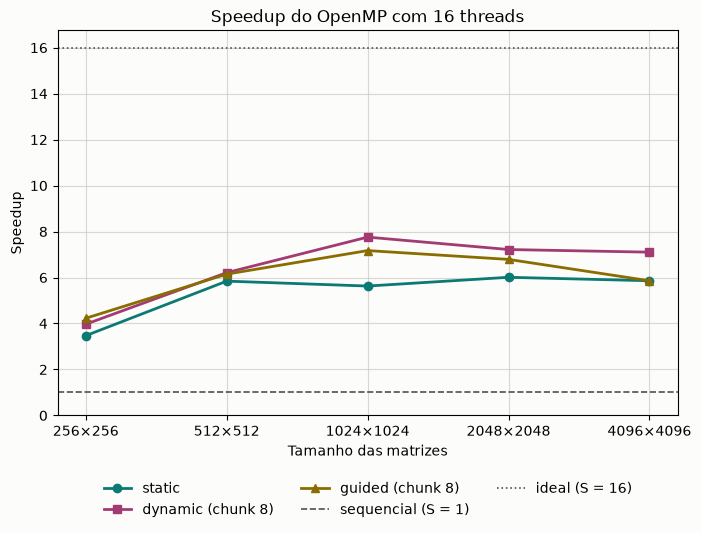

In [19]:
COLORS = {"static": "#0b7a75", "dynamic": "#a23b72", "guided": "#8a6d00"}
MARKERS = {"static": "o", "dynamic": "s", "guided": "^"}

fig, ax = plt.subplots(figsize=(8, 5), facecolor=SURF)
ax.set_facecolor(SURF)
positions = list(range(len(SIZES)))        # os tamanhos dobram a cada passo e as posições são igualmente espaçadas

for policy, schedule in FAMILIES.items():
    d = speedup_table[(speedup_table["escalonamento"] == schedule) & (speedup_table["threads"] == CPUS)]
    d = d.set_index("n").loc[SIZES]
    label = policy if policy == "static" else f"{policy} (chunk {schedule.split(',')[1]})"
    ax.plot(positions, d["speedup"], marker=MARKERS[policy], color=COLORS[policy], lw=2, label=label)

ax.axhline(1, color=MUTED, linestyle="--", lw=1.2, label="sequencial (S = 1)")
ax.axhline(CPUS, color=MUTED, linestyle=":", lw=1.2, label=f"ideal (S = {CPUS})")

ax.set_xticks(positions)
ax.set_xticklabels([f"{n}×{n}" for n in SIZES])
ax.set_xlabel("Tamanho das matrizes")
ax.set_ylabel("Speedup")
ax.set_ylim(bottom=0)
ax.set_title(f"Speedup do OpenMP com {CPUS} threads")
ax.grid(True, color=GRID, alpha=0.7)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3)   # legenda abaixo, fora das curvas
save_figure(fig, "openmp_speedup")

### Implementação com memória distribuída (MPI)

Com $P$ ranks, o rank $r$ recebe $q+[r<s]$ linhas a partir de $rq+min(r,s)$, em que $q=\lfloor n/P\rfloor$ e $s=n\bmod P$. O rank 0 prepara as matrizes. O `Scatterv` usa contagens e deslocamentos em elementos de $A$, e o `Gatherv` usa os mesmos intervalos de linhas com a largura de $C$. Todos recebem $B$ por `Bcast` e calculam suas linhas com o laço `i-j-k`.

Cada rank mantém $mp$ valores de $B$ mais suas faixas de $A$ e $C$. O rank 0 mantém também as matrizes completas. Para $n=m=p=4096$, só a réplica de $B$ exige 128 MiB por rank. Os contadores MPI usados pelo código limitam cada matriz a `INT_MAX` elementos.

O rank 0 cronometra da primeira coletiva até o recebimento de $C$ completo. A linha `DETAIL` registra os nós usados, os tempos nas coletivas vistos pelo rank 0 e o maior tempo local no laço entre os ranks. O tempo registrado em `Gatherv` pode incluir espera por ranks mais lentos.

In [20]:
write_source('mpi.c', r"""#include "common.h"
#include <mpi.h>

int main(int argc, char **argv) {
    MPI_Init(&argc, &argv);
    int rank, ranks;
    MPI_Comm_rank(MPI_COMM_WORLD, &rank);
    MPI_Comm_size(MPI_COMM_WORLD, &ranks);

    /* Todos os ranks validam os argumentos, mas só o rank 0 imprime a mensagem de erro. */
    dims_t d;
    const char *error = NULL;
    if (!try_parse_dims(argc, argv, &d))
        error = "uso";
    else if (d.n > INT_MAX / d.m || d.m > INT_MAX / d.p || d.n > INT_MAX / d.p)
        error = "Matrizes excedem o limite de contagens int das coletivas MPI";
    if (error) {
        if (rank == 0) {
            if (strcmp(error, "uso") == 0) print_usage(argv[0]);
            else fprintf(stderr, "%s\n", error);
        }
        MPI_Finalize();
        return EXIT_FAILURE;
    }

    int base = d.n / ranks, rest = d.n % ranks;
    int rows = base + (rank < rest);
    double *local_A = alloc_matrix(rows, d.m, 0);
    double *local_C = alloc_matrix(rows, d.p, 1);
    double *B = alloc_matrix(d.m, d.p, 0);
    double *A = NULL, *C = NULL;
    int *a_counts = NULL, *a_offsets = NULL, *c_counts = NULL, *c_offsets = NULL;
    if (rank == 0) {
        A = alloc_matrix(d.n, d.m, 0);
        C = alloc_matrix(d.n, d.p, 0);
        init_matrices(d, A, B);

        int *layout = malloc(4 * (size_t)ranks * sizeof(*layout));
        if (!layout) {
            fprintf(stderr, "Falha ao alocar a distribuição MPI\n");
            MPI_Abort(MPI_COMM_WORLD, EXIT_FAILURE);
        }
        a_counts = layout;
        a_offsets = a_counts + ranks;
        c_counts = a_offsets + ranks;
        c_offsets = c_counts + ranks;
        int first = 0;
        for (int r = 0; r < ranks; r++) {
            int count = base + (r < rest);
            a_counts[r] = count * d.m;
            a_offsets[r] = first * d.m;
            c_counts[r] = count * d.p;
            c_offsets[r] = first * d.p;
            first += count;
        }
    }

    MPI_Comm node;
    MPI_Comm_split_type(MPI_COMM_WORLD, MPI_COMM_TYPE_SHARED, rank, MPI_INFO_NULL, &node);
    int node_rank;
    MPI_Comm_rank(node, &node_rank);
    int leader = (node_rank == 0), nodes = 0;
    MPI_Reduce(&leader, &nodes, 1, MPI_INT, MPI_SUM, 0, MPI_COMM_WORLD);
    MPI_Comm_free(&node);

    MPI_Barrier(MPI_COMM_WORLD);
    double t0 = MPI_Wtime();
    MPI_Scatterv(A, a_counts, a_offsets, MPI_DOUBLE,
                 local_A, rows * d.m, MPI_DOUBLE, 0, MPI_COMM_WORLD);
    double t1 = MPI_Wtime();
    MPI_Bcast(B, d.m * d.p, MPI_DOUBLE, 0, MPI_COMM_WORLD);
    double t2 = MPI_Wtime();

    /* Cada rank calcula suas linhas com o mesmo núcleo i-j-k da versão sequencial. */
    matmul_rows(d, 0, rows, local_A, B, local_C);

    double t3 = MPI_Wtime();
    MPI_Gatherv(local_C, rows * d.p, MPI_DOUBLE,
                C, c_counts, c_offsets, MPI_DOUBLE, 0, MPI_COMM_WORLD);
    double t4 = MPI_Wtime();

    double local_compute = t3 - t2, max_compute = 0.0;
    MPI_Reduce(&local_compute, &max_compute, 1, MPI_DOUBLE, MPI_MAX, 0, MPI_COMM_WORLD);
    int valid = 1;
    if (rank == 0) {
        valid = verify_matrix(d, A, B, C);
        if (valid) {
            report("mpi", d, ranks, t4 - t0, checksum(d, C));
            printf("DETAIL,mpi,%d,%.9f,%.9f,%.9f,%.9f\n",
                   nodes, t1 - t0, t2 - t1, max_compute, t4 - t3);
        }
    }
    free(a_counts);
    free(A);
    free(B);
    free(C);
    free(local_A);
    free(local_C);
    MPI_Finalize();
    return valid ? EXIT_SUCCESS : EXIT_FAILURE;
}
""")

Fonte preparada: mpi.c


In [21]:
compile_c("mpi.c", "mpi", compiler="mpicc")
print(subprocess.check_output(["mpicc", "-show"], text=True).strip())
MPI_CMD = "mpirun --oversubscribe --bind-to none"
MPI_ENV = {"OMPI_ALLOW_RUN_AS_ROOT": "1", "OMPI_ALLOW_RUN_AS_ROOT_CONFIRM": "1"}

rows = []
for n, m, p in [*VALIDATION_CASES, (2, 19, 17)]:
    ref = reference_checksum(n, m, p)
    for ranks in (1, 3, 4):
        res = run_once(f"{MPI_CMD} -np {ranks} {BIN}/mpi {n} {m} {p}",
                       env={**MPI_ENV, "MATMUL_VERIFY": "1"})
        assert res["workers"] == ranks and res["nodes"] == 1, res
        assert np.isclose(res["checksum"], ref, rtol=1e-9, atol=1e-12), res
        rows.append(dict(n=n, m=m, p=p, ranks=ranks, checksum=res["checksum"]))
pd.DataFrame(rows)

mpicc -O3 /tmp/matmul-dfu8n4bv/src/mpi.c -o /tmp/matmul-dfu8n4bv/bin/mpi
gcc -I/usr/lib/x86_64-linux-gnu/openmpi/include -I/usr/lib/x86_64-linux-gnu/openmpi/include/openmpi -L/usr/lib/x86_64-linux-gnu/openmpi/lib -lmpi


,n,m,p,ranks,checksum
0,256,256,256,1,5033027.45
1,256,256,256,3,5033027.45
2,256,256,256,4,5033027.45
3,300,200,400,1,7199976.59
4,300,200,400,3,7199976.59
5,300,200,400,4,7199976.59
6,513,127,64,1,1250836.31
7,513,127,64,3,1250836.31
8,513,127,64,4,1250836.31
9,1,1000,1,1,299.66


#### Execução local e no OpenHPC da UFSCar

A célula de medição abaixo executa o MPI no ambiente do notebook, com todos os ranks na mesma máquina. É com essas medições que a Análise de desempenho compara MPI, OpenMP e GPU.

Como complemento opcional, o MPI também pode ser executado no cluster OpenHPC da UFSCar, para comparar o mesmo total de ranks em um e em dois nós. A célula seguinte grava o script de submissão em `scripts/openhpc.sbatch`, no diretório de execução do notebook. No cluster, carregue o ambiente MPI da disciplina, entre no diretório que contém o script e o diretório `src/` e envie os jobs. O exemplo usa PMIx; ajuste o tipo MPI, a conta e a partição conforme a configuração do OpenHPC.

```bash
MPI_TYPE=pmix sbatch --nodes=1 --ntasks=8 --ntasks-per-node=8 scripts/openhpc.sbatch
MPI_TYPE=pmix sbatch --nodes=2 --ntasks=8 --ntasks-per-node=4 scripts/openhpc.sbatch
```

Cada job valida um caso retangular, mede a referência sequencial na própria alocação e registra o número de nós efetivamente usados pelo MPI. Para incluir os resultados na análise, copie os arquivos `matmul-openhpc-*.log` para o diretório do notebook (no Colab, pela aba **Arquivos**). Sem esses arquivos, a análise usa apenas as medições locais.

In [22]:
# Grava o script de submissão do OpenHPC (e os fontes que ele compila) no diretório de execução.
OPENHPC_SBATCH = r"""#!/usr/bin/env bash
#SBATCH --job-name=matmul
#SBATCH --time=00:30:00
#SBATCH --cpus-per-task=1
#SBATCH --output=matmul-openhpc-%j.log

set -euo pipefail

cd "${SLURM_SUBMIT_DIR:?Envie o job a partir da raiz do repositório}"
nodes=${SLURM_JOB_NUM_NODES:?Execute com sbatch}
slots=${SLURM_NTASKS:?Defina --ntasks ou --ntasks-per-node em sbatch}
reps=${REPS:-5}
[[ $reps =~ ^[1-9][0-9]*$ ]]
if (( $# == 0 )); then set -- 256 512 1024 2048; fi

export OMP_NUM_THREADS=1 MATMUL_VERIFY=0 LC_ALL=C
build=$(mktemp -d "$PWD/.matmul-${SLURM_JOB_ID}.XXXXXX")
trap 'rm -f "$build/sequential" "$build/mpi"; rmdir "$build"' EXIT
gcc -O3 src/sequential.c -o "$build/sequential"
mpicc -O3 src/mpi.c -o "$build/mpi"

echo "RUN,openhpc,$SLURM_JOB_ID,$nodes,$reps"
echo "Data (UTC): $(date -u +%FT%TZ)"
echo "Versão do código: $(git rev-parse --short HEAD 2>/dev/null || echo arquivo)"
echo "Nós da alocação:"
scontrol show hostnames "$SLURM_JOB_NODELIST"
gcc --version | sed -n '1p'
mpicc -show
if command -v ompi_info >/dev/null; then
    ompi_info --version
elif command -v mpichversion >/dev/null; then
    mpichversion
fi
srun --nodes=1 --ntasks=1 --exact lscpu

mpi_flags=()
if [[ -n ${MPI_TYPE:-} ]]; then mpi_flags+=(--mpi="$MPI_TYPE"); fi

run_mpi() {
    local ranks=$1
    shift
    local output
    output=$(srun --nodes="$nodes" --ntasks="$ranks" --exact --distribution=block:block \
        --cpu-bind=cores --kill-on-bad-exit=1 "${mpi_flags[@]}" "$build/mpi" "$@")
    if ! awk -F, -v ranks="$ranks" -v nodes="$nodes" '
        $1 == "RESULT" { results++; actual_ranks = $6 }
        $1 == "DETAIL" { details++; actual_nodes = $3 }
        END { exit !(results == 1 && details == 1 && actual_ranks == ranks && actual_nodes == nodes) }
    ' <<< "$output"; then
        printf 'Esperados %s ranks em %s nó(s). Confira o tipo MPI do srun.\n%s\n' \
            "$ranks" "$nodes" "$output" >&2
        return 1
    fi
    printf '%s\n' "$output"
}

# Uma dimensão retangular com resto exercita a divisão em todos os nós alocados.
validation=$(MATMUL_VERIFY=1 run_mpi "$slots" "$((slots * 4 + 1))" 23 31)
echo "Validação elemento a elemento com $slots ranks em $nodes nó(s) concluída."
printf '%s\n' "$validation" | sed 's/^/VALIDATION,/'

ranks_to_test=("$slots")
if (( nodes == 1 )); then
    ranks_to_test=()
    for (( ranks = 1; ranks < slots; ranks *= 2 )); do ranks_to_test+=("$ranks"); done
    ranks_to_test+=("$slots")
fi

for n in "$@"; do
    for (( rep = 1; rep <= reps; rep++ )); do
        srun --nodes=1 --ntasks=1 --exact --cpu-bind=cores "$build/sequential" "$n"
        for ranks in "${ranks_to_test[@]}"; do
            run_mpi "$ranks" "$n"
        done
    done
done
echo "DONE,openhpc,$SLURM_JOB_ID"
"""

(RUN_DIR / "scripts").mkdir(exist_ok=True)
(RUN_DIR / "scripts" / "openhpc.sbatch").write_text(OPENHPC_SBATCH, encoding="utf-8")
(RUN_DIR / "src").mkdir(exist_ok=True)
for name in ("common.h", "sequential.c", "mpi.c"):
    shutil.copy(SRC / name, RUN_DIR / "src" / name)
print("Script gravado em", RUN_DIR / "scripts" / "openhpc.sbatch")

Script gravado em /home/gubuntu/UFSCar/PPD/matrix-multiplication/scripts/openhpc.sbatch


In [23]:
for n in SIZES:
    for ranks in THREADS:
        benchmark(f"{MPI_CMD} -np {ranks} {BIN}/mpi {n}", env=MPI_ENV)

mpi                 n= 256 workers=   1 | 0.005541 ± 0.001446 s


mpi                 n= 256 workers=   2 | 0.003384 ± 0.001156 s


mpi                 n= 256 workers=   4 | 0.001725 ± 0.000045 s


mpi                 n= 256 workers=   8 | 0.001882 ± 0.000172 s


mpi                 n= 256 workers=  16 | 0.003408 ± 0.001378 s


mpi                 n= 512 workers=   1 | 0.028896 ± 0.000139 s


... (15 outputs left out)

mpi                 n=4096 workers=   2 | 13.470276 ± 0.078032 s


mpi                 n=4096 workers=   4 | 10.779463 ± 0.050937 s


mpi                 n=4096 workers=   8 | 8.770098 ± 0.101792 s


mpi                 n=4096 workers=  16 | 8.558898 ± 0.003671 s


### Implementação em GPU com CUDA

Cada bloco de $16\times16$ threads cobre um *tile* do resultado. A thread `(x, y)` calcula $C[i,k]$, com $i=16\cdot\text{blockIdx.y}+y$ e $k=16\cdot\text{blockIdx.x}+x$. A grade usa arredondamento para cima nas duas dimensões de $C$.

1. Para cada faixa de 16 valores de $j$, as threads carregam um *tile* de $A$ e outro de $B$ da memória global para a compartilhada. Posições de borda fora da matriz recebem zeros.
2. Uma barreira espera o carregamento. Cada thread acumula 16 produtos usando a linha de $A$ e a coluna de $B$ do *tile*. Outra barreira protege os dados até que todas as threads terminem de lê-los.
3. Ao final, cada thread dentro de $C$ grava o próprio resultado. Threads de borda participam das barreiras e só descartam a escrita final quando a coordenada está fora de $C$.

Cada bloco usa $2\cdot16^2\cdot8=4096$ bytes de memória compartilhada para os dois *tiles*. O código usa FP64 como as versões de CPU. Em GPUs GeForce RTX 4050/4060, a taxa de FP64 é menor que a de FP32, por isso o resultado deve ser interpretado como a aceleração deste algoritmo em FP64. O tempo principal inclui as duas entradas e a saída pelo barramento, e eventos CUDA medem o kernel. Em dimensões que não são múltiplas de 16, a taxa em GFLOP/s usa o trabalho útil $2nmp$.

In [24]:
write_source('cuda.cu', r"""#include "common.h"
#include <cuda_runtime.h>

constexpr int TILE = 16;

static void check_cuda(cudaError_t status, const char *operation) {
    if (status != cudaSuccess) {
        fprintf(stderr, "%s: %s\n", operation, cudaGetErrorString(status));
        exit(EXIT_FAILURE);
    }
}

#define CUDA(call) check_cuda((call), #call)

__global__ void matmul_cuda(dims_t d, const double *A, const double *B, double *C) {
    __shared__ double tile_A[TILE][TILE];
    __shared__ double tile_B[TILE][TILE];
    const int x = threadIdx.x, y = threadIdx.y;
    const int i = blockIdx.y * TILE + y, k = blockIdx.x * TILE + x;
    double sum = 0.0;

    for (int tile = 0; tile <= (d.m - 1) / TILE; tile++) {
        int a_col = tile * TILE + x, b_row = tile * TILE + y;
        tile_A[y][x] = (i < d.n && a_col < d.m) ? A[(size_t)i * d.m + a_col] : 0.0;
        tile_B[y][x] = (b_row < d.m && k < d.p) ? B[(size_t)b_row * d.p + k] : 0.0;
        __syncthreads();

        for (int j = 0; j < TILE; j++)
            sum += tile_A[y][j] * tile_B[j][x];
        // Todas as threads devem terminar a leitura antes de carregar o próximo tile.
        __syncthreads();
    }
    if (i < d.n && k < d.p) C[(size_t)i * d.p + k] = sum;
}

int main(int argc, char **argv) {
    dims_t d = parse_dims(argc, argv);
    const dim3 block(TILE, TILE);
    const dim3 grid(1 + (d.p - 1) / TILE, 1 + (d.n - 1) / TILE);
    int device;
    cudaDeviceProp props;
    CUDA(cudaGetDevice(&device));
    CUDA(cudaGetDeviceProperties(&props, device));
    if (grid.x > (unsigned)props.maxGridSize[0] || grid.y > (unsigned)props.maxGridSize[1] ||
        (size_t)grid.x * grid.y > INT_MAX) {
        fprintf(stderr, "Dimensões excedem a capacidade da grade CUDA\n");
        return EXIT_FAILURE;
    }

    double *A = alloc_matrix(d.n, d.m, 0);
    double *B = alloc_matrix(d.m, d.p, 0);
    double *C = alloc_matrix(d.n, d.p, 0);
    init_matrices(d, A, B);
    size_t a_bytes = (size_t)d.n * d.m * sizeof(double);
    size_t b_bytes = (size_t)d.m * d.p * sizeof(double);
    size_t c_bytes = (size_t)d.n * d.p * sizeof(double);
    double *device_A, *device_B, *device_C;
    CUDA(cudaMalloc(&device_A, a_bytes));
    CUDA(cudaMalloc(&device_B, b_bytes));
    CUDA(cudaMalloc(&device_C, c_bytes));
    cudaEvent_t start, stop;
    CUDA(cudaEventCreate(&start));
    CUDA(cudaEventCreate(&stop));
    /* Força o carregamento do kernel antes da medição: no CUDA 12 os módulos são
     * carregados sob demanda, e esse custo cairia dentro do tempo do kernel. */
    cudaFuncAttributes attributes;
    CUDA(cudaFuncGetAttributes(&attributes, matmul_cuda));

    double t0 = wall_time();
    CUDA(cudaMemcpy(device_A, A, a_bytes, cudaMemcpyHostToDevice));
    CUDA(cudaMemcpy(device_B, B, b_bytes, cudaMemcpyHostToDevice));
    CUDA(cudaDeviceSynchronize());
    double t1 = wall_time();
    CUDA(cudaEventRecord(start));
    matmul_cuda<<<grid, block>>>(d, device_A, device_B, device_C);
    CUDA(cudaGetLastError());
    CUDA(cudaEventRecord(stop));
    CUDA(cudaEventSynchronize(stop));
    double t2 = wall_time();
    CUDA(cudaMemcpy(C, device_C, c_bytes, cudaMemcpyDeviceToHost));
    double t3 = wall_time();

    float kernel_ms = 0.0f;
    CUDA(cudaEventElapsedTime(&kernel_ms, start, stop));
    int valid = verify_matrix(d, A, B, C);
    if (valid) {
        report("cuda", d, (int)(grid.x * grid.y), t3 - t0, checksum(d, C));
        printf("DETAIL,cuda,%.9f,%.9f,%.9f\n", t1 - t0, kernel_ms * 1e-3, t3 - t2);
    }
    CUDA(cudaEventDestroy(start));
    CUDA(cudaEventDestroy(stop));
    CUDA(cudaFree(device_A));
    CUDA(cudaFree(device_B));
    CUDA(cudaFree(device_C));
    free(A);
    free(B);
    free(C);
    return valid ? EXIT_SUCCESS : EXIT_FAILURE;
}
""")

Fonte preparada: cuda.cu


In [25]:
GPU_READY = False
if shutil.which("nvidia-smi") and shutil.which("nvcc"):
    found = subprocess.run(["nvidia-smi", "--query-gpu=name,driver_version", "--format=csv,noheader"],
                           capture_output=True, text=True)
    GPU_READY = found.returncode == 0 and bool(found.stdout.strip())
    if GPU_READY:
        GPU_INFO = found.stdout.strip()
        print(GPU_INFO)
        print(subprocess.check_output(["nvcc", "--version"], text=True).strip())
        compile_c("cuda.cu", "cuda", compiler="nvcc", flags="-O3 -arch=native")

if GPU_READY:
    rows = []
    for n, m, p in VALIDATION_CASES:
        res = run_once(f"{BIN}/cuda {n} {m} {p}", env={"MATMUL_VERIFY": "1"})
        assert res["workers"] == ((n + 15)//16)*((p + 15)//16), res
        assert np.isclose(res["checksum"], reference_checksum(n, m, p), rtol=1e-9, atol=1e-12), res
        rows.append(dict(n=n, m=m, p=p, blocos=res["workers"], checksum=res["checksum"]))
    display(pd.DataFrame(rows))
    for n in SIZES:
        benchmark(f"{BIN}/cuda {n}")
else:
    print("Medições CUDA pendentes. Use uma GPU NVIDIA com nvcc ou o ambiente GPU do Colab.")

NVIDIA GeForce RTX 4050 Laptop GPU, 595.99.02
nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2023 NVIDIA Corporation
Built on Fri_Jan__6_16:45:21_PST_2023
Cuda compilation tools, release 12.0, V12.0.140
Build cuda_12.0.r12.0/compiler.32267302_0


nvcc -O3 -arch=native /tmp/matmul-dfu8n4bv/src/cuda.cu -o /tmp/matmul-dfu8n4bv/bin/cuda


,n,m,p,blocos,checksum
0,256,256,256,256,5033027.45
1,300,200,400,475,7199976.59
2,513,127,64,132,1250836.31
3,1,1000,1,1,299.66
4,500,1,300,608,44867.94
5,17,23,31,4,3631.00
6,33,31,18,6,5511.00


cuda                n= 256 workers= 256 | 0.000680 ± 0.000012 s


cuda                n= 512 workers=1024 | 0.003124 ± 0.000042 s


cuda                n=1024 workers=4096 | 0.018581 ± 0.000219 s


cuda                n=2048 workers=16384 | 0.106897 ± 0.010971 s


cuda                n=4096 workers=65536 | 0.730993 ± 0.000698 s


### Análise de desempenho

Usamos a média e o desvio padrão amostral de cinco execuções por configuração, mantendo fixo o tamanho das matrizes em cada comparação de escalabilidade forte. O *speedup* é $S=T_{seq}/T_{par}$ e a eficiência CPU é $S/P$ para $P$ threads ou ranks. A taxa é $2nmp / T_{par}$ em GFLOP/s. A referência sequencial de cada ambiente ou job é medida na mesma execução do estudo. O ajuste de escalonamento OpenMP fica fora da amostra principal.

A fração de tempo do rank 0 nas coletivas indica quanto do tempo ele permanece nessas chamadas, incluindo esperas. O máximo dos tempos de computação dos ranks tem um relógio lógico diferente dessas fases e pode se sobrepor à espera em `Gatherv`. Para CUDA, a análise mostra a fração de tempo das cópias e a taxa do kernel, além da taxa de ponta a ponta.

In [26]:
def load_openhpc(path):
    lines = path.read_text(encoding="utf-8").splitlines()
    header = next(line for line in lines if line.startswith("RUN,openhpc,"))
    _, _, job, expected_nodes, expected_reps = header.split(",")
    assert f"DONE,openhpc,{job}" in lines, f"Job ainda não concluído em {path.name}"
    counters, runs = {}, []
    for i, line in enumerate(lines):
        if not line.startswith("RESULT,"):
            continue
        following = lines[i + 1] if i + 1 < len(lines) else ""
        res = parse_output(line + "\n" + following if following.startswith("DETAIL,") else line)
        if res["impl"] == "mpi":
            assert res["nodes"] == int(expected_nodes), (path, res)
        key = (res["impl"], res["n"], res["m"], res["p"], res["workers"])
        counters[key] = counters.get(key, 0) + 1
        runs.append({**res, "run": f"OpenHPC {job}", "phase": "principal", "rep": counters[key]})
    assert counters and set(counters.values()) == {int(expected_reps)}, f"Job incompleto em {path.name}"
    assert {r["impl"] for r in runs} == {"sequential", "mpi"}, path.name
    return runs


local = pd.DataFrame(RESULTS).assign(data_utc=RUN_DATE, cpu=CPU_MODEL, gpu=GPU_INFO)
local.to_csv(RUN_DIR / "matmul-local.csv", index=False)
logs = sorted(RUN_DIR.glob("matmul-openhpc-*.log"))
cluster = [res for path in logs for res in load_openhpc(path)]
if not cluster:
    print("Nenhum log do OpenHPC encontrado: a análise usa apenas as medições locais.")

runs = pd.DataFrame([*RESULTS, *cluster]).query("phase == 'principal'").copy()
keys = ["run", "n", "m", "p"]
reference = runs.query("impl == 'sequential'").groupby(keys)["checksum"].first().rename("ref")
checked = runs.join(reference, on=keys)
assert np.isclose(checked["checksum"], checked["ref"], rtol=1e-9, atol=1e-12).all()
print(f"{len(runs)} medições principais com checksum validado.")
runs["collectives_s"] = runs[["scatter_s", "bcast_s", "gather_s"]].sum(axis=1, min_count=3)
for col in ("h2d_s", "kernel_s", "d2h_s"):
    if col not in runs:
        runs[col] = np.nan
runs["copies_s"] = runs["h2d_s"] + runs["d2h_s"]

summary = (runs.groupby([*keys, "impl", "nodes", "workers"])
           .agg(reps=("time_s", "size"), mean_s=("time_s", "mean"), std_s=("time_s", "std"),
                collectives_s=("collectives_s", "mean"), max_compute_s=("compute_max_s", "mean"),
                scatter_s=("scatter_s", "mean"), bcast_s=("bcast_s", "mean"),
                gather_s=("gather_s", "mean"), copies_s=("copies_s", "mean"), kernel_s=("kernel_s", "mean"))
           .reset_index())
seq_time = summary.query("impl == 'sequential'").set_index(keys)["mean_s"].rename("seq_s")
summary = summary.join(seq_time, on=keys)
summary["speedup"] = summary["seq_s"] / summary["mean_s"]
summary["efficiency"] = (summary["speedup"] / summary["workers"]).where(summary["impl"] != "cuda")
summary["GFLOP_s"] = 2 * summary["n"] * summary["m"] * summary["p"] / (summary["mean_s"] * 1e9)
summary["GFLOP_s_kernel"] = summary["GFLOP_s"] * summary["mean_s"] / summary["kernel_s"]
summary["coletivas_%"] = 100 * summary["collectives_s"] / summary["mean_s"]
summary["copias_%"] = 100 * summary["copies_s"] / summary["mean_s"]
with pd.option_context("display.max_rows", 120):
    display(summary[["run", "impl", "n", "nodes", "workers", "reps", "mean_s", "std_s",
                     "speedup", "efficiency", "GFLOP_s"]].round(4))

Nenhum log do OpenHPC encontrado: a análise usa apenas as medições locais.
550 medições principais com checksum validado.


,run,impl,n,nodes,workers,reps,mean_s,std_s,speedup,efficiency,GFLOP_s
0,local,cuda,256,1,256,5,0.0007,0.0000,6.2387,NaN,49.3621
1,local,mpi,256,1,1,5,0.0055,0.0014,0.7653,0.7653,6.0552
2,local,mpi,256,1,2,5,0.0034,0.0012,1.2533,0.6266,9.9163
3,local,mpi,256,1,4,5,0.0017,0.0000,2.4581,0.6145,19.4492
4,local,mpi,256,1,8,5,0.0019,0.0002,2.2529,0.2816,17.8257
5,local,mpi,256,1,16,5,0.0034,0.0014,1.2444,0.0778,9.8460
6,local,openmp-dynamic-8,256,1,1,5,0.0037,0.0006,1.1429,1.1429,9.0433
7,local,openmp-dynamic-8,256,1,2,5,0.0027,0.0002,1.5688,0.7844,12.4130
8,local,openmp-dynamic-8,256,1,4,5,0.0016,0.0003,2.6410,0.6602,20.8960
9,local,openmp-dynamic-8,256,1,8,5,0.0010,0.0001,4.2373,0.5297,33.5270


#### Ambiente e melhores configurações

A tabela mostra, para cada tamanho, o melhor tempo médio de cada implementação (o menor entre todas as quantidades de threads ou ranks e, no OpenMP, entre todas as políticas de escalonamento), com o *speedup* em relação à versão sequencial medida na mesma execução.

In [27]:
print(f"CPU: {CPU_MODEL}")
print(f"GPU: {GPU_INFO or 'não disponível'}")
print(f"Threads/ranks testados: {THREADS} | repetições por configuração: {REPS}")

local_summary = summary.query("run == @LOCAL_RUN").copy()
local_summary["familia"] = local_summary["impl"].str.split("-").str[0]
FAMILY_LABEL = {"sequential": "Sequencial", "openmp": "OpenMP", "mpi": "MPI", "cuda": "CUDA"}

best = (local_summary.loc[local_summary.groupby(["familia", "n"])["mean_s"].idxmin()]
        .assign(implementacao=lambda d: d["familia"].map(FAMILY_LABEL)))
best_table = best.pivot_table(index="n", columns="implementacao", values="mean_s")
best_table = best_table[[c for c in ["Sequencial", "OpenMP", "MPI", "CUDA"] if c in best_table]]
speedup_best = best.pivot_table(index="n", columns="implementacao", values="speedup")
config_best = best.set_index(["n", "implementacao"])[["impl", "workers"]]

display(Markdown("**Melhor tempo médio (s)**"))
display(best_table.round(4))
display(Markdown("**Speedup da melhor configuração em relação à versão sequencial**"))
display(speedup_best[[c for c in best_table if c != "Sequencial"]].round(2))
display(Markdown("**Configuração que obteve o melhor tempo**"))
display(config_best.unstack("implementacao").swaplevel(axis=1).sort_index(axis=1))

CPU: 13th Gen Intel(R) Core(TM) i5-13450HX
GPU: NVIDIA GeForce RTX 4050 Laptop GPU, 595.99.02
Threads/ranks testados: [1, 2, 4, 8, 16] | repetições por configuração: 5


**Melhor tempo médio (s)**

implementacao,Sequencial,OpenMP,MPI,CUDA
n,,,,
256,0.0042,0.0010,0.0017,0.0007
512,0.0276,0.0044,0.0133,0.0031
1024,0.2021,0.0261,0.1150,0.0186
2048,2.8023,0.3882,1.1124,0.1069
4096,24.1447,3.3993,8.5589,0.7310


**Speedup da melhor configuração em relação à versão sequencial**

implementacao,OpenMP,MPI,CUDA
n,,,
256,4.24,2.46,6.24
512,6.21,2.08,8.85
1024,7.76,1.76,10.88
2048,7.22,2.52,26.22
4096,7.10,2.82,33.03


**Configuração que obteve o melhor tempo**

implementacao  CUDA          MPI                    OpenMP          \
               impl workers impl workers              impl workers   
n                                                                    
256            cuda     256  mpi       4  openmp-dynamic-8       8   
512            cuda    1024  mpi       4  openmp-dynamic-8      16   
1024           cuda    4096  mpi       8  openmp-dynamic-8      16   
2048           cuda   16384  mpi      16  openmp-dynamic-8      16   
4096           cuda   65536  mpi      16  openmp-dynamic-8      16   

implementacao  Sequencial          
                     impl workers  
n                                  
256            sequential       1  
512            sequential       1  
1024           sequential       1  
2048           sequential       1  
4096           sequential       1

Os números discutidos a seguir são os desta execução, feita em um notebook com processador Intel Core i5-13450HX (6 P-cores com *hyper-threading* e 4 E-cores, 16 threads, 20 MiB de L3) e GPU NVIDIA GeForce RTX 4050 Laptop. Se o notebook for executado em outra máquina, os valores mudam, mas as tendências devem se manter.

Com $n = 4096$, a versão sequencial levou 24,1 s. A melhor configuração OpenMP (`dynamic,8` com 16 threads) levou 3,40 s, um *speedup* de 7,1×. O melhor MPI (16 ranks) levou 8,56 s, ou 2,8×. A GPU levou 0,73 s, incluindo as cópias, o que dá 33× em relação à versão sequencial e 4,7× em relação ao melhor OpenMP. Com uma thread, o OpenMP (23,6 s) e com um rank o MPI (23,5 s) ficam praticamente iguais à versão sequencial, o que confirma que as três versões de CPU executam o mesmo laço e que o *speedup* mede apenas o efeito da paralelização.

#### Comparação entre as implementações

À esquerda, o tempo da melhor configuração de cada implementação em função do tamanho (escala logarítmica). À direita, o *speedup* correspondente.

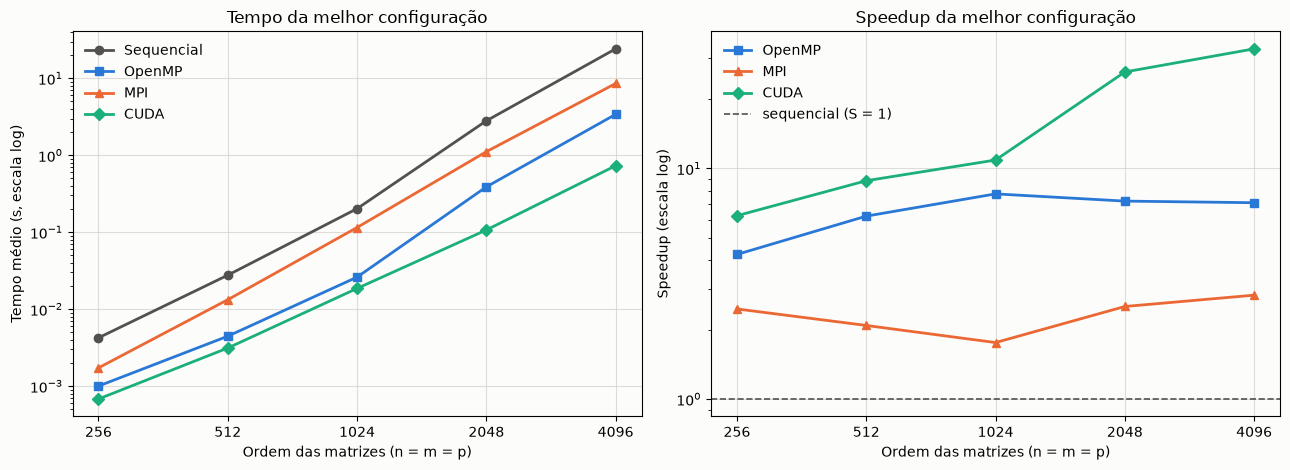

In [28]:
IMPL_COLORS = {"Sequencial": MUTED, "OpenMP": "#2a78d6", "MPI": "#eb6834", "CUDA": "#1baf7a"}
IMPL_MARKERS = {"Sequencial": "o", "OpenMP": "s", "MPI": "^", "CUDA": "D"}
positions = list(range(len(SIZES)))
ticks = [f"{n}" for n in SIZES]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), facecolor=SURF)
ax = axes[0]
for impl in best_table:
    ax.plot(positions, best_table[impl].reindex(SIZES), marker=IMPL_MARKERS[impl],
            color=IMPL_COLORS[impl], lw=2, label=impl)
ax.set_yscale("log")
ax.set(xlabel="Ordem das matrizes (n = m = p)", ylabel="Tempo médio (s, escala log)",
       title="Tempo da melhor configuração")
ax = axes[1]
for impl in [c for c in best_table if c != "Sequencial"]:
    ax.plot(positions, speedup_best[impl].reindex(SIZES), marker=IMPL_MARKERS[impl],
            color=IMPL_COLORS[impl], lw=2, label=impl)
ax.axhline(1, color=MUTED, linestyle="--", lw=1.2, label="sequencial (S = 1)")
ax.set_yscale("log")
ax.set(xlabel="Ordem das matrizes (n = m = p)", ylabel="Speedup (escala log)",
       title="Speedup da melhor configuração")
for ax in axes:
    ax.set_facecolor(SURF)
    ax.set_xticks(positions)
    ax.set_xticklabels(ticks)
    ax.grid(True, color=GRID, alpha=0.6)
    ax.legend(frameon=False)
fig.tight_layout()
save_figure(fig, "comparison")

Três comportamentos aparecem nos gráficos.

O primeiro é o efeito do tamanho do problema. Em matrizes pequenas, o custo fixo de cada versão pesa mais que o cálculo: criar o time de threads, iniciar as coletivas MPI ou copiar os dados para a GPU. Com $n = 256$, o cálculo sequencial leva só 4 ms, e a GPU é apenas 1,5× mais rápida que o OpenMP, porque 67% do seu tempo vai para as cópias. À medida que $n$ cresce, o trabalho cresce com $n^3$ e os custos fixos com $n^2$ ou menos, e as versões paralelas se aproximam do seu limite.

O segundo é a mudança de inclinação entre $n = 1024$ e $n = 2048$. É nesse ponto que a matriz $B$ (8 MiB com $n = 1024$, 32 MiB com $n = 2048$) deixa de caber no L3 de 20 MiB. A versão sequencial cai de 10,6 para 6,1 GFLOP/s, e o OpenMP para de ganhar *speedup* (7,8× em 1024, 7,1× em 4096), porque as threads passam a depender da banda da memória principal, que é compartilhada. A GPU, ao contrário, melhora: seu *speedup* salta de 10,9× para 26×, porque ela não depende do cache da CPU e porque matrizes maiores geram mais blocos para ocupar os multiprocessadores.

O terceiro é a ordem entre as implementações, que é a mesma em todos os tamanhos: GPU, OpenMP, MPI e sequencial. As seções seguintes explicam por que o MPI fica atrás do OpenMP mesmo com o mesmo número de *workers* e a mesma decomposição.

#### Escalabilidade em CPU

Os gráficos mostram o *speedup* e a eficiência ($E = S/P$) em função do número de threads (OpenMP, uma curva por política) ou de ranks (MPI), para o maior tamanho medido. A linha pontilhada é o caso ideal.

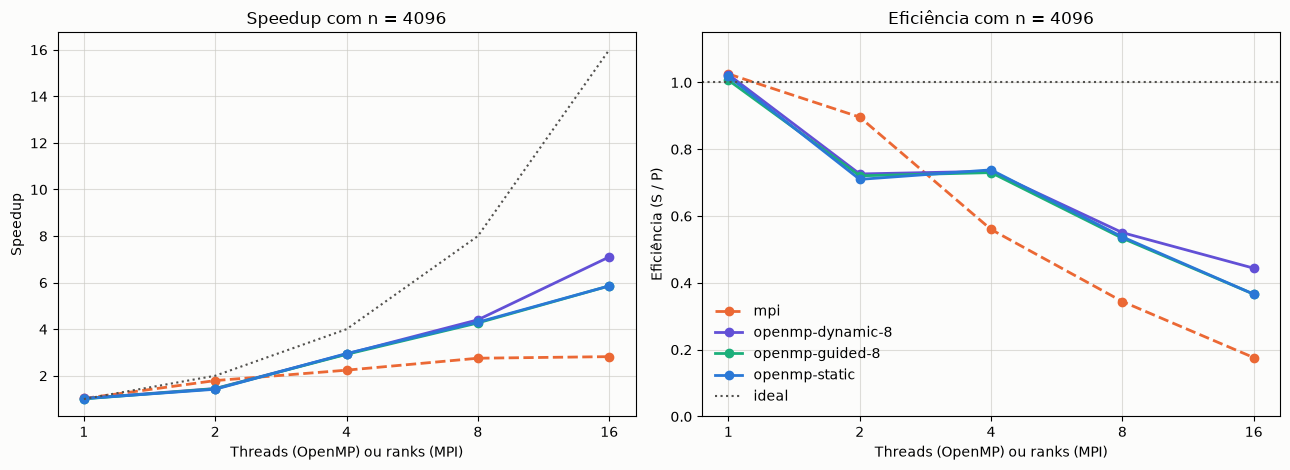

**Tempo médio (s) com n = 4096, por número de threads ou ranks**

impl,mpi,openmp-dynamic-8,openmp-guided-8,openmp-static
workers,,,,
1,23.5436,23.5873,23.9821,23.7150
2,13.4703,16.6272,16.7551,17.0081
4,10.7795,8.2222,8.2676,8.1754
8,8.7701,5.4833,5.6562,5.6146
16,8.5589,3.3993,4.1213,4.1208


In [29]:
largest = max(SIZES)
cpu = local_summary.query("n == @largest and familia in ['openmp', 'mpi']")
SCALING_COLORS = {"openmp-static": "#2a78d6", "openmp-dynamic": "#6250d6", "openmp-guided": "#1baf7a", "mpi": "#eb6834"}

def scaling_key(impl):
    return impl if impl == "mpi" else "-".join(impl.split("-")[:2])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), facecolor=SURF)
for impl, data in cpu.groupby("impl"):
    data = data.sort_values("workers")
    color = SCALING_COLORS[scaling_key(impl)]
    style = "--" if impl == "mpi" else "-"
    axes[0].plot(data["workers"], data["speedup"], marker="o", ls=style, color=color, lw=2, label=impl)
    axes[1].plot(data["workers"], data["efficiency"], marker="o", ls=style, color=color, lw=2, label=impl)
axes[0].plot(THREADS, THREADS, ls=":", color=MUTED, label="ideal")
axes[1].axhline(1, ls=":", color=MUTED, label="ideal")
axes[0].set(ylabel="Speedup", title=f"Speedup com n = {largest}")
axes[1].set(ylabel="Eficiência (S / P)", title=f"Eficiência com n = {largest}", ylim=(0, 1.15))
for ax in axes:
    ax.set_facecolor(SURF)
    ax.set_xscale("log", base=2)
    ax.set_xticks(THREADS)
    ax.set_xticklabels(THREADS)
    ax.set_xlabel("Threads (OpenMP) ou ranks (MPI)")
    ax.grid(True, color=GRID, alpha=0.6)
axes[1].legend(frameon=False, loc="lower left")
fig.tight_layout()
save_figure(fig, "cpu_scaling")

display(Markdown(f"**Tempo médio (s) com n = {largest}, por número de threads ou ranks**"))
display(cpu.pivot_table(index="workers", columns="impl", values="mean_s").round(4))

Até 8 threads, as três políticas de escalonamento do OpenMP têm praticamente o mesmo tempo (diferenças dentro do desvio padrão). Com 16 threads, `dynamic,8` é 17% mais rápido que `static` (3,40 s contra 4,12 s). Isso confirma a hipótese da modelagem sobre o balanceamento de carga: a carga por linha é uniforme, mas os núcleos não são. Com 16 threads, algumas rodam nos E-cores ou dividem um P-core com outra thread, e terminam suas linhas depois das demais. No `static`, cada thread recebe 256 linhas fixas e as mais rápidas ficam esperando. No `dynamic,8`, as threads mais rápidas simplesmente pegam mais blocos de 8 linhas. O `guided` começa com blocos grandes e só os reduz no final, e nesta máquina ficou igual ao `static`.

O ajuste do *chunk* (feito com $n = 1024$) também mostra o efeito da granularidade. *Chunks* de 128 linhas foram os piores, porque 1024 linhas divididas em blocos de 128 dão apenas 8 blocos para 16 threads, e metade das threads fica sem trabalho. Já *chunks* de 1 linha aumentam o número de acessos ao escalonador. O melhor ponto foi 8 linhas, que gera 128 blocos, o suficiente para redistribuir a carga sem custo perceptível de escalonamento.

A eficiência do OpenMP cai de forma gradual: 0,73 com 4 threads, 0,55 com 8 e 0,44 com 16. Duas causas contribuem. A primeira é o hardware: só 6 dos 16 *threads* são P-cores completos, e as threads de *hyper-threading* dividem as unidades de ponto flutuante do mesmo núcleo, então o *speedup* ideal real é menor que 16. A segunda é a banda de memória: com $n = 4096$, $B$ não cabe no L3 e todas as threads leem da memória principal. O caso de 2 threads, com eficiência de 0,72, teve variação grande entre execuções; testes com afinidade de threads (`OMP_PROC_BIND`) não mudaram o resultado de forma consistente, e a hipótese mais provável é a redução da frequência de *turbo* quando mais de um núcleo está ativo, comum em processadores de notebook.

O MPI escala muito pior: eficiência de 0,56 com 4 ranks e 0,18 com 16, com o tempo quase parado entre 8 e 16 ranks (8,77 s e 8,56 s).

#### Decomposição do tempo do MPI

Para entender a diferença entre MPI e OpenMP, separamos o tempo do MPI nas suas fases: as três coletivas, vistas pelo rank 0, e o maior tempo de cálculo entre os ranks. O tempo em `Gatherv` inclui a espera pelos ranks que terminam por último.

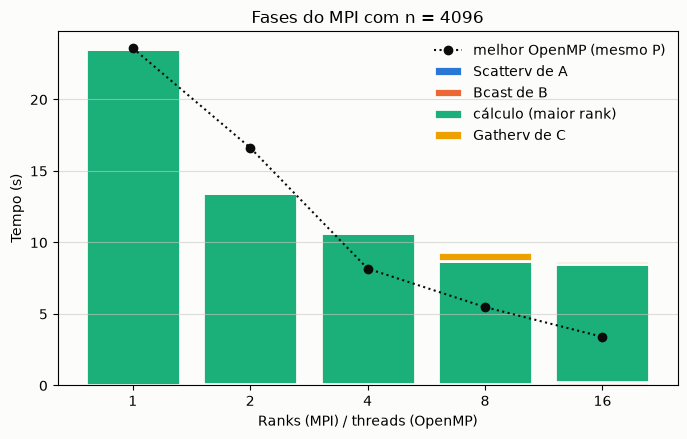

,workers,mean_s,scatter_s,bcast_s,max_compute_s,gather_s,coletivas_%,calculo_ideal_s,omp_mesmo_P_s
89,1,23.5436,0.0467,0.0000,23.4494,0.0474,0.3999,23.4494,23.5873
90,2,13.4703,0.0474,0.0470,13.3340,0.0534,1.0975,11.7247,16.6272
91,4,10.7795,0.0467,0.0468,10.5935,0.1167,1.9500,5.8624,8.1754
92,8,8.7701,0.0497,0.0681,8.6206,0.5753,7.9027,2.9312,5.4833
93,16,8.5589,0.0615,0.1645,8.2642,0.1883,4.8401,1.4656,3.3993


In [30]:
mpi = local_summary.query("impl == 'mpi' and n == @largest").sort_values("workers")
phases = {"scatter_s": ("Scatterv de A", "#2a78d6"), "bcast_s": ("Bcast de B", "#eb6834"),
          "max_compute_s": ("cálculo (maior rank)", "#1baf7a"), "gather_s": ("Gatherv de C", "#eda100")}

fig, ax = plt.subplots(figsize=(8, 4.6), facecolor=SURF)
ax.set_facecolor(SURF)
labels = [str(w) for w in mpi["workers"]]
bottom = np.zeros(len(mpi))
for col, (name, color) in phases.items():
    ax.bar(labels, mpi[col], bottom=bottom, color=color, label=name, edgecolor=SURF, linewidth=2)
    bottom += mpi[col].to_numpy()
omp_best = (local_summary.query("familia == 'openmp' and n == @largest")
            .groupby("workers")["mean_s"].min().reindex(mpi["workers"]))
ax.plot(labels, omp_best, color=INK, marker="o", ls=":", lw=1.5, label="melhor OpenMP (mesmo P)")
ax.set(xlabel="Ranks (MPI) / threads (OpenMP)", ylabel="Tempo (s)", title=f"Fases do MPI com n = {largest}")
ax.grid(True, axis="y", color=GRID, alpha=0.6)
ax.legend(frameon=False)
save_figure(fig, "mpi_phases")

mpi_table = mpi[["workers", "mean_s", "scatter_s", "bcast_s", "max_compute_s", "gather_s", "coletivas_%"]].copy()
mpi_table["calculo_ideal_s"] = mpi_table["max_compute_s"].iloc[0] / mpi_table["workers"]
mpi_table["omp_mesmo_P_s"] = omp_best.to_numpy()
mpi_table.round(4)

O gráfico mostra que o problema do MPI **não é a comunicação**. As três coletivas somam no máximo 8% do tempo (0,41 s de 8,56 s com 16 ranks). O `Bcast` de $B$, que a modelagem apontava como o maior custo, leva 0,16 s com 16 ranks, porque, com todos os processos na mesma máquina, as mensagens passam pela memória compartilhada. Quase todo o tempo é de **cálculo**: com 16 ranks, o rank mais lento leva 8,26 s, enquanto a divisão perfeita do trabalho sequencial daria 1,47 s.

A explicação está na decomposição combinada com a memória. Cada rank recebe sua própria cópia de $B$, então com 16 ranks há 16 cópias de 128 MiB em endereços diferentes. Todos os ranks percorrem a sua cópia inteira para cada linha que calculam, e nenhuma linha de cache trazida por um rank serve para outro. A banda da memória principal é dividida entre 16 fluxos independentes e se esgota: dobrar o número de ranks de 8 para 16 praticamente não muda o tempo.

No OpenMP, a decomposição é a mesma, mas as threads leem **a mesma cópia** de $B$. Como todas começam a percorrer $B$ ao mesmo tempo e avançam em ritmo parecido, uma linha de $B$ trazida para o L3 por uma thread costuma ser reaproveitada pelas outras logo em seguida. O tráfego com a memória principal é muito menor e o OpenMP continua ganhando até 16 threads. Com poucos *workers* a situação se inverte: com 2 ranks, o MPI (13,5 s) foi mais rápido que o OpenMP com 2 threads (16,6 s).

Para matrizes pequenas aparece o outro limite, o da granularidade: com $n = 256$ e $n = 1024$, 16 ranks são **mais lentos** que 8 (com $n = 512$ empatam), porque cada rank tem pouco trabalho e o custo fixo das coletivas passa a pesar. Com $n = 1024$, o melhor MPI usa 8 ranks e atinge só 1,8×.

Essa análise também mostra a limitação do experimento: em um *cluster*, cada nó tem sua própria memória, e as cópias de $B$ em nós diferentes não disputariam a mesma banda. Por outro lado, a comunicação passaria pela rede e deixaria de ser desprezível. O experimento opcional no OpenHPC, com o mesmo número de ranks em um e em dois nós, mede exatamente essa troca.

#### GPU

A tabela separa o tempo da GPU em cópias para a GPU (*host → device*), kernel e cópia de volta (*device → host*). O desempenho é dado em GFLOP/s de ponta a ponta (incluindo as cópias) e só do kernel.

In [31]:
if GPU_READY:
    cuda_runs = runs.query("run == @LOCAL_RUN and impl == 'cuda'")
    gpu_table = (cuda_runs.groupby("n")[["time_s", "h2d_s", "kernel_s", "d2h_s"]].mean()
                 .rename(columns={"time_s": "total_s"}))
    gpu_table["copias_%"] = 100 * (gpu_table["h2d_s"] + gpu_table["d2h_s"]) / gpu_table["total_s"]
    flops = 2 * gpu_table.index.to_series() ** 3
    gpu_table["GFLOP_s_total"] = flops / gpu_table["total_s"] / 1e9
    gpu_table["GFLOP_s_kernel"] = flops / gpu_table["kernel_s"] / 1e9
    gpu_table["speedup_vs_seq"] = best_table["Sequencial"] / gpu_table["total_s"]
    gpu_table["speedup_vs_melhor_OpenMP"] = best_table["OpenMP"] / gpu_table["total_s"]
    print(subprocess.check_output(["nvidia-smi", "--query-gpu=name,clocks.max.sm,memory.total",
                                   "--format=csv,noheader"], text=True).strip())
    display(gpu_table.round(4))
else:
    print("Sem GPU neste ambiente: a tabela da GPU não foi gerada.")

NVIDIA GeForce RTX 4050 Laptop GPU, 3105 MHz, 6141 MiB


,total_s,h2d_s,kernel_s,d2h_s,copias_%,GFLOP_s_total,GFLOP_s_kernel,speedup_vs_seq,speedup_vs_melhor_OpenMP
n,,,,,,,,,
256,0.0007,0.0002,0.0002,0.0003,67.3444,49.3621,155.6397,6.2387,1.4723
512,0.0031,0.0006,0.0016,0.0009,48.3412,85.9380,167.0871,8.8465,1.4241
1024,0.0186,0.0017,0.0131,0.0037,29.4486,115.5745,163.9130,10.8788,1.4023
2048,0.1069,0.0064,0.0869,0.0136,18.7068,160.7145,197.7155,26.2150,3.6320
4096,0.7310,0.0248,0.6558,0.0504,10.2898,188.0168,209.5853,33.0300,4.6503


Com $n = 4096$, o kernel atinge 210 GFLOP/s. A RTX 4050 Laptop tem 20 multiprocessadores e, como as GPUs GeForce da arquitetura Ada, executa operações em `double` a 1/64 da taxa de `float`: são 4 operações de precisão dupla por ciclo em cada multiprocessador. Com o *clock* entre 2,6 GHz (sustentado) e 3,1 GHz (máximo informado pelo `nvidia-smi`), o pico teórico fica entre cerca de 210 e 250 GFLOP/s. O kernel com *tiling* opera, portanto, perto do limite de computação da placa em FP64. O *tiling* em memória compartilhada cumpre seu papel: cada valor de $A$ e $B$ lido da memória global é reaproveitado 16 vezes dentro do bloco, e o kernel deixa de ser limitado pela memória.

A fração das cópias entre CPU e GPU mostra o papel da comunicação na GPU. As cópias movem $3n^2$ valores, enquanto o kernel faz $2n^3$ operações, então seu peso diminui com o tamanho: 67% do tempo com $n = 256$, 29% com $n = 1024$ e 10% com $n = 4096$. Para matrizes pequenas, a GPU passa mais tempo transportando dados do que calculando, e a vantagem sobre o OpenMP é pequena (1,4× a 1,5× até $n = 1024$). Para matrizes grandes, as cópias se diluem e a vantagem chega a 4,7×.

A GPU também confirma a escolha de granularidade da modelagem: com uma thread por elemento, $n = 4096$ gera 16,8 milhões de threads em 65.536 blocos, e o desempenho do kernel cresce com o tamanho (156 GFLOP/s com $n = 256$, 210 GFLOP/s com $n = 4096$), porque há mais blocos para ocupar os 20 multiprocessadores e esconder a latência da memória.

Vale notar que este resultado é em precisão dupla, para comparar com as versões de CPU. Em `float`, a mesma GPU teria um pico 64 vezes maior, e a diferença em relação à CPU seria muito maior.

### Conclusões

As medições confirmam as decisões da modelagem e mostram onde estão os limites de cada plataforma.

A **decomposição do resultado em faixas de linhas** permitiu paralelizar sem nenhuma sincronização no cálculo, e as três versões de CPU produzem exatamente o mesmo resultado que a versão sequencial. A escolha de um núcleo de cálculo único (`matmul_rows`) foi necessária para uma comparação justa: com o laço escrito diretamente na região OpenMP, o compilador gerava um código 25% mais lento, que seria confundido com custo de paralelização.

Quanto ao **balanceamento de carga**, a carga uniforme torna o `static` suficiente enquanto os núcleos são iguais. Com todos os 16 threads da máquina, a heterogeneidade entre P-cores e E-cores faz o `dynamic,8` ser 17% mais rápido, como previsto.

Quanto à **granularidade**, cada plataforma tem um tamanho mínimo de problema a partir do qual compensa. Para matrizes pequenas, os custos fixos (coletivas MPI, cópias para a GPU, *chunks* muito grandes no OpenMP) dominam. Para matrizes grandes, o cálculo domina.

Quanto à **comunicação**, a previsão da modelagem se confirmou na GPU, onde as cópias pesam muito em matrizes pequenas e pouco nas grandes. No MPI em uma única máquina, as coletivas custaram menos de 8% do tempo. O que limitou o MPI foi a consequência da decomposição 1D sobre a memória: replicar $B$ em cada processo multiplica o tráfego com a memória principal, enquanto as threads OpenMP compartilham uma única cópia no cache.

Quanto à **localidade**, a queda de desempenho quando $B$ deixa de caber no L3 aparece em todas as versões de CPU, e a GPU, com *tiling* em memória compartilhada, chega perto do pico da placa. Isso indica o próximo passo natural para as versões de CPU: aplicar *tiling* também na CPU, dividindo $B$ em blocos que caibam no cache e reaproveitando cada bloco para várias linhas de $A$, o que atacaria diretamente o limite de banda que restringe tanto o OpenMP quanto, principalmente, o MPI.

No total, a GPU foi a plataforma mais adequada para este problema, com *speedup* de 33× em $n = 4096$, seguida pelo OpenMP (7,1×) e pelo MPI (2,8×). O MPI é a única das três que escala para além de uma máquina, e seu desempenho em um *cluster* dependeria do equilíbrio entre a banda de memória própria de cada nó e o custo da rede.